# Discovering recurring AI risk themes in OECD AIM reports
### Clustering capstone · Simona Barbuceanu · Tomorrow University
**Study period:** 1 July–30 September 2026 (exported report dates).  
**Research question:** To what extent can text clustering reveal recurring AI harm themes in OECD AIM reports, rather than simply grouping reports about the same company or news story?

**Study status:** a completed exploratory study with provisional relevance screening. The clusters are candidate review queues, not a validated taxonomy of harmful events. Throughout, I separate what was measured from what still needs human verification.

**Reading guide:** Sections 1–7 contain the technical study; Section 8 reflects on framing and methods; Section 9 is an impact brief for non-technical readers (about five minutes). Everything needed to understand the results is in this notebook. No separate report is required.

**Reproduction:** the saved notebook contains executed results. The package omits original exported titles and summaries while reuse clarification is pending. With the private input CSV in `data/`, all experiments recompute; without it, the notebook explicitly loads saved aggregates to reproduce the figures. Replaying aggregates is **not** re-running clustering. Section 2.4 explains how to obtain the data and which mode to run; `data/README.md` repeats the same steps.

## 1. Problem framing and project proposal
AI governance reviewers need to organise many reports of actual or potential harm. A media-based collection may repeat the same story, name a prominent company repeatedly, or mix different harms in one report. A cluster therefore does not automatically represent a distinct risk or an independent event.

The objective is to test whether a transparent text pipeline can support an initial reading queue. Success means finding interpretable candidate groups while exposing instability and entity effects. It does not mean estimating the prevalence or severity of AI harms, predicting future incidents, or assigning legal responsibility.

Three questions guide the analysis:
1. Which recurring descriptive themes emerge, and what governance questions could they inform?
2. How do text representation and clustering algorithm change separation and stability?
3. How do company/product names, provisional exclusions and possible event overlap affect the partition?

**Unit of analysis:** an exported AIM report. Reports are not assumed to be independent events. Both reported incidents (actual harm) and hazards (plausible potential harm) are in scope, but the export does not provide reliable labels separating them. The OECD methodology provides this conceptual distinction; this project does not manufacture missing labels.

**Sustainability and equity:** the study can help reviewers notice environmental resource concerns, surveillance and privacy, exploitation and other human impacts. It cannot measure unequal exposure across demographic groups because the data does not contain suitable denominators or consistent demographic variables. Any recommendation to protect vulnerable people is a proposed use, not an evaluated social outcome.

### 1.1 Problem Statement & Hypothesis
**Problem statement.** The collected OECD AI Incidents and Hazards Monitor (AIM) sample averages about 630 reports per month during this quarter; this is a sample statistic, not a measured workload for any governance team. The export contains no consistent harm labels that could sort these reports for reading. I want to know whether unsupervised clustering of the report text can produce **harm-themed reading queues**, meaning groups of reports a reviewer could read together, rather than groups that only reflect which company or news story attracted coverage.

**Exploratory hypotheses.** These are working expectations informed by the data context and feasibility pilot, not preregistered hypotheses or confirmatory statistical tests. The summaries are short (about 47 words) and describe what went wrong, but the monitor is media-based, a few firms dominate coverage, and in my January–February 2025 pilot DeepSeek mentions shaped the groups.

| | Expected cluster pattern | Dataset features that make it plausible | How it is tested | What would count against it |
|---|---|---|---|---|
| **H1: harm mechanism** | Groups organised by how harm happens, e.g. fraud and voice impersonation, facial recognition and surveillance, sexual deepfake abuse, election misinformation, autonomous-vehicle safety | Title + summary text; mechanism words and phrases (*scam*, *facial recognition*, *deepfake*, *self driving*) kept as unigrams and bigrams in TF-IDF | Top terms and central examples per cluster (Section 6) | Most clusters defined by company names or generic AI words rather than harm vocabulary |
| **H2: entity/news effect (rival)** | Some groups organised around a company or product (e.g. OpenAI, Tesla, Meta) rather than a type of harm | Company and product names in titles and summaries; repeated coverage of the same story; the `companies` field is empty, so names enter only through the text | Share of each cluster mentioning ten names (heatmap, Section 6); refit with names masked, compared by ARI (Section 5.2) | Name shares low in every cluster, and membership almost unchanged after masking (ARI close to 1) |
| **H3: weak separation** | Overlapping groups, including at least one large mixed group, because many reports mention several harms and share generic AI vocabulary | Short summaries with few informative words each; reports combining multiple harms or general warnings | Cosine silhouette in the original TF-IDF space, share of reports with negative silhouette, seed and subset ARI (Section 5) | Clearly positive silhouettes and near-identical membership across seeds and subsets |

**Link to the problem.** If H1 holds and H2 is limited, the clusters could serve as reading queues for reviewers. If H2 dominates, the clusters mostly mirror media attention and would mislead anyone who used them to set priorities. H3 motivates human checking; these diagnostics do not determine how much checking is sufficient. Section 7 reports the verdict on each hypothesis.

## 2. Dataset selection, provenance and access
### 2.1 Dataset Selection and justification
I chose the **OECD AI Incidents and Hazards Monitor (AIM)**, reports dated 1 July–30 September 2026, because it fits the problem on three counts and could support the intended beneficiaries' review work.

| Aspect | Evidence from this dataset | Why it matters for the problem |
|---|---|---|
| **Relevance to the issue** | AIM is an international, public monitor of AI incidents (actual harm) and hazards (plausible harm), with a published methodology. The collection is intended to cover AI incidents and hazards, but individual exported records still need relevance checks. | The problem is about organising AI-harm reports for governance review, so the unit of data is exactly what reviewers have to read and triage. |
| **Sample size** | 1,889 unique reports in one complete quarter (581 / 599 / 709 per month), with reports on every one of the 92 days. | Large enough for 4–12 groups of at least 20 reports each and for 80% subset stability tests. Small enough that full pairwise cosine matrices (about 1,845 × 1,845) and average-linkage clustering fit in memory, and that a targeted close review of 181 summaries was feasible. |
| **Features** | Seven fields: `id`, `title`, `date`, `summary`, `concepts`, `companies`, `country`. Title and summary are present for every report and summaries are uniform in length (37–63 words). | Free text is the only field that is complete and describes the harm itself, so it supports H1 and H2 directly. `companies` is empty and `country` is incomplete. `concepts` is an upstream classification, so it is kept out of the features to avoid building pre-existing labels into an unsupervised result. Stable IDs and dates support validation, deduplication checks and annotation joins. |

**Who benefits, and how this choice serves them**
- **AI governance and risk-review teams** (for example in public bodies, regulators or company AI-ethics functions): could use public incident monitors; queues built from AIM reports offer a workflow to test with them. Actual use and workflow fit were not measured.
- **Policy and programme teams**: theme-level groups can broaden consultation questions and scenario planning beyond the most-covered stories.
- **Researchers**: a fixed, checksum-verified snapshot and a text-only pipeline let others test the method or repeat it on another quarter.
- **People affected by AI harms**, indirectly: the reports describe harms to consumers (fraud), children (sexual-image abuse), residents near data centres (water and energy) and people under surveillance. Better-organised review is meant to make these harms easier to notice, including smaller groups.

**Selection limits.** AIM is media-based and largely English-language, so beneficiaries see only harms that were reported, and under-reported groups or regions are likely missing. One quarter supports exploration, not trend estimates. The earlier pilot was a feasibility test and is not pooled with this study.

### 2.2 Provenance, completeness and access
The main sample contains 1,889 unique reports exported from the [OECD AI Incidents and Hazards Monitor](https://oecd.ai/en/incidents). The collection manifest records retrieval on **23 October 2026**. Exported dates are report dates, not necessarily event dates.

The completed quarter was selected for recency and enough material before its clustering results were examined. An earlier January–February 2025 sample was a feasibility pilot; it is not pooled into this study. This quarter contains far fewer DeepSeek mentions, but other entities may still drive grouping.

The collection used 22 overlapping official Excel exports because downloads were capped at 100 rows. There were 2,164 downloaded rows, with 275 repeated IDs across batches; the combined file has 1,889 unique IDs. The count matched the monitor snapshot, and every day in the quarter appears. This supports collection completeness relative to that snapshot, **not** completeness of worldwide AI harms. Later changes to the monitor may prevent exact recollection.

The seven original fields are `id`, `title`, `date`, `summary`, `concepts`, `companies`, `country`. All reports have titles and summaries. Country is missing for 59 rows; companies is empty throughout. Missing metadata is not filled with guesses. Only title and summary enter clustering; IDs and dates support checks, and all other fields are excluded from feature building.

The [OECD methodology and disclosures](https://oecd.ai/en/incidents-methodology) describe a media-based monitor and third-party material. We analyse descriptions, not independently verified events. Redistribution clarification is pending. This package includes loading instructions and our annotations, rather than the source text. This is a packaging decision, not a legal conclusion that every form of academic processing requires separate permission.

### 2.3 Environment, paths and execution mode
Run from either the project root or `notebooks/`. Python 3.12 and exact tested dependency versions are listed in `requirements.txt`. An ordinary Jupyter environment can open and run this notebook. No cloud AI service or paid API is required.

The input hash prevents a silently revised dataset from being presented as the same experiment. A new snapshot runs in its own explicitly labelled mode (Section 2.4) and writes to a separate results folder. Numeric cluster IDs have no rank or persistent meaning.

### 2.4 How to obtain the data and run the notebook
The submitted folder does not include the source text: OECD has not yet confirmed whether the exported titles and summaries may be redistributed (Section 2). The notebook therefore runs in one of three clearly labelled modes:

| Mode | What you need | What happens |
|---|---|---|
| **Aggregate replay** (default when no CSV is present) | Only this project folder | Every cell runs. Figures and tables are rebuilt from saved results in `results/`. Clustering is **not** recomputed. |
| **Exact recomputation** | `data/oecd_aim_q3_2026.csv`, the studied snapshot | All validation, exploration, 28 experiments, stability and sensitivity tests recompute. The SHA-256 checksum confirms the file is byte-for-byte the studied snapshot. |
| **New snapshot** | A newly collected CSV and the environment variable `CAPSTONE_SNAPSHOT_MODE=new` | The same pipeline runs on a different dataset. Checks specific to the exact snapshot are relaxed, results go to `results_new_snapshot/`, and theme labels always fall back to top terms. The numbers in the markdown text do **not** describe this run. |

**Obtaining the exact snapshot.** The original seven-column file is held separately in `oecd-aim-jul-sep-2026-reviewed-sample.zip`. Copy `oecd-aim-2026-07-01-to-2026-09-30.csv` into `data/` and rename it `oecd_aim_q3_2026.csv`. Don't open and re-save it in Excel, because that changes the bytes and the checksum. Assessors who need full recomputation can request private access to this file.

**Collecting a new snapshot from OECD.AI:**
1. Open the [OECD AI Incidents and Hazards Monitor](https://oecd.ai/en/incidents) and filter report dates from 1 July to 30 September 2026. Check the dates in the exported file, not only the filter shown in the URL.
2. Use the official download button. During collection each download returned at most 100 rows. Work backwards from the latest date, and start each new batch on the oldest day of the previous batch so no partial days are lost (the batch dates used here are in `data/collection_manifest.json`).
3. Save every Excel export in one folder, then combine them by report ID:
   `python data/load_exports.py path/to/exports --output data/oecd_aim_new_snapshot.csv`
   The helper stops if the same ID appears with conflicting content, trims to the study window and prints counts and a checksum.
4. Compare the number of unique reports with the quarter total shown on the website. The monitor can revise past records, so a new snapshot is expected to differ from the studied one.
5. Run the notebook with `CAPSTONE_SNAPSHOT_MODE=new` (for example, `CAPSTONE_SNAPSHOT_MODE=new jupyter lab`). Every report is marked `unreviewed_new_snapshot` and kept for an exploratory run. Old review flags are not transferred by ID alone: a report's text may have changed. Repeat scope and event screening before interpreting themes.

In [ ]:
from pathlib import Path
import re, json, hashlib, platform
import numpy as np
import pandas as pd
import scipy, sklearn, matplotlib
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score, silhouette_samples
from sklearn.metrics.pairwise import cosine_distances, cosine_similarity
from scipy.cluster.hierarchy import linkage, fcluster

SEED=42
KS=[4,6,8,10,12]
NAMES={'OpenAI':r'\bopenai\b','Anthropic':r'\banthropic\b','Meta':r'\bmeta\b','Google':r'\bgoogle\b','Claude':r'\bclaude\b','ChatGPT':r'\bchatgpt\b','Tesla':r'\btesla\b','DeepSeek':r'\bdeepseek\b','Grok':r'\bgrok\b','Gemini':r'\bgemini\b'}

import matplotlib.pyplot as plt
import time
from IPython.display import display
from threadpoolctl import threadpool_limits

import os

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'data/review_annotations.csv').exists(), 'Open the notebook from the project folder.'

# Execution mode (see Section 2.4):
#   'exact' (default): the studied 23 Oct 2026 snapshot, verified by checksum.
#   'new': a separately collected snapshot. Checks for the exact snapshot are
#          relaxed, results go to results_new_snapshot/, and the narrative numbers
#          in the markdown do NOT describe that run.
SNAPSHOT_MODE = os.environ.get('CAPSTONE_SNAPSHOT_MODE', 'exact')
assert SNAPSHOT_MODE in {'exact', 'new'}, "SNAPSHOT_MODE must be 'exact' or 'new'."
EXACT = SNAPSHOT_MODE == 'exact'
# Keep the reference before a full recomputation writes any aggregate outputs.
RECORDED_PROFILES = json.loads((ROOT / 'results/summary.json').read_text())['profiles']
STUDY_START, STUDY_END = '2026-07-01', '2026-09-30'   # inclusive report-date window
if EXACT:
    DATA = ROOT / 'data/oecd_aim_q3_2026.csv'
    OUT = ROOT / 'results'
else:
    DATA = ROOT / os.environ.get('CAPSTONE_NEW_SNAPSHOT', 'data/oecd_aim_new_snapshot.csv')
    OUT = ROOT / 'results_new_snapshot'
    assert DATA.exists(), f'New-snapshot mode needs {DATA}. Build it with data/load_exports.py.'
OUT.mkdir(exist_ok=True)
FULL_RECOMPUTE = DATA.exists()
EXPECTED_SHA256 = 'bcaf26d36fe5634c267188d39aece923e4b13f6f6464a5deea9208409d166da1'
if not EXACT:
    print('NEW SNAPSHOT MODE: a different dataset from the studied snapshot; markdown figures do not describe this run.')
print('FULL RECOMPUTE from source text' if FULL_RECOMPUTE else 'AGGREGATE REPLAY: source text absent; clustering is not recomputed')
print('Python:', platform.python_version())
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 10, 'figure.facecolor': 'white'})

FULL RECOMPUTE from source text
Python: 3.12.14


### 2.5 Load and validate the source
In full mode, these checks confirm the exact bytes, column schema, dates, uniqueness and missing values before any fitting. In replay mode the notebook reads saved measured values and says so. No synthetic dataset is ever substituted for unavailable source data.

In [ ]:
review = pd.read_csv(ROOT / 'data/review_annotations.csv', keep_default_na=False)
assert review.id.is_unique
if FULL_RECOMPUTE:
    if EXACT:
        assert hashlib.sha256(DATA.read_bytes()).hexdigest() == EXPECTED_SHA256, 'Input differs from the studied snapshot.'
    raw = pd.read_csv(DATA, keep_default_na=False)
    required = ['id','title','date','summary','concepts','companies','country']
    assert raw.columns.tolist() == required
    assert raw.id.is_unique
    assert raw[['id','title','summary']].apply(lambda x: x.str.strip().ne('').all()).all()
    dates = pd.to_datetime(raw.date, errors='raise')
    assert dates.between(STUDY_START, STUDY_END).all()
    if EXACT:
        # Exact-snapshot assertions: count, full daily coverage and annotation keys.
        assert len(raw) == 1889
        assert dates.nunique() == 92
        assert raw.id.tolist() == review.id.tolist(), 'Annotation order/source keys differ.'
    else:
        print(f'New snapshot: all {len(raw)} reports require fresh review; old ID-keyed decisions will not be transferred.')
    print('Source validated:', len(raw), 'reports;', dates.nunique(), 'distinct days')
    print('Missing cells by field:\n' + raw.eq('').sum().to_string())
    print('Exact repeated titles:', raw.title.duplicated().sum())
    print('Exact repeated summaries:', raw.summary.duplicated().sum())
    lengths = raw.summary.str.split().str.len()
    print('Summary word counts:\n' + lengths.describe().round(1).to_string())
else:
    print('Source validation skipped: load the private CSV to run it. Recorded exploration results are shown in Section 2.6.')
if EXACT:
    print('Annotation status counts:\n' + review.relevance_status.value_counts().to_string())
else:
    print('All new-snapshot records await fresh scope and event review.')

Source validated: 1889 reports; 92 distinct days
Missing cells by field:
id              0
title           0
date            0
summary         0
concepts        0
companies    1889
country        59
Exact repeated titles: 0
Exact repeated summaries: 0
Summary word counts:
count    1889.0
mean       47.5
std         2.9
min        37.0
25%        46.0
50%        47.0
75%        49.0
max        63.0
Annotation status counts:
relevance_status
provisional_keep_not_fully_adjudicated    1845
needs_scope_or_source_review                38
exclude_pilot                                6


### 2.6 Dataset profiling: structure and quality
Before cleaning or modelling, I profiled the export with six checks. The cell below recomputes them in full mode and saves aggregates only, with no titles or summaries, to `results/eda.json`. In replay mode it shows the recorded values.

| Check | Result | Consequence for the analysis |
|---|---|---|
| **Variable types** | No numeric variables. `id`: unique string key. `title`, `summary`: free text. `date`: calendar date (92 distinct days). `concepts`: multi-value text tags (a different combination in every report). `companies`: text, empty throughout. `country`: categorical text (81 distinct values; United States 725 reports, then China 127). | Text has to be vectorised (Section 3). Only title and summary become features; `id` and `date` are used for validation and joins. |
| **Missing values** | `companies` empty for all 1,889 reports; `country` empty for 59; every other field complete. | No imputation. Neither field is used as a feature, so empty metadata is not directly encoded in clustering. Reporting and missingness patterns can still reflect selection biases. |
| **Duplicates** | IDs unique; no exact repeated titles or summaries. The close review still found 19 candidate families of related reports (41 reports). | Exact deduplication isn't needed, but near-repeats are handled in Section 2.7 and a sensitivity test. |
| **Outliers** | Summary length 37–63 words (median 47, interquartile range 46–49). Using 1.5 × IQR fences (41.5–53.5 words), 77 summaries (4.1%) are statistical outliers: 29 shorter and 48 longer, none by more than 10 words. | Not removed: these length differences are plausible. Normalisation reduces vector-magnitude effects but does not guarantee length has no influence. Rare-term filtering is vocabulary control, not a content-outlier detector; DBSCAN noise provides only a representation- and parameter-dependent outlier diagnostic (Section 5). |
| **Scaling needs** | No numeric scale differences to standardise. For text, raw word counts favour frequent, uninformative words and longer texts. | TF-IDF down-weights common words, sublinear term frequency limits repetition, L2 normalisation reduces length-related magnitude differences and LSA vectors are re-normalised. Evaluation and hierarchical/DBSCAN distances are cosine; ordinary K-means fitting uses Euclidean distance (Sections 3–4). Because lengths vary by only a few words (SD 2.9), length is unlikely to drive distances. |
| **Temporal coverage** | Reports on all 92 days (5–38 per day, median 21); 581 / 599 / 709 per month. | Supports completeness relative to the monitor snapshot. The September rise reflects coverage captured, not the frequency of harm. |

The charts show monthly volume, missing values by field, a Tukey box plot and a histogram of summary length with the outlier fences marked, the ten most frequent country values, and the most widespread words. Country concentration (38% United States) and the dominance of generic words such as *risks*, *harm* and *concerns* support two later choices: excluding country from the features, and down-weighting common words with TF-IDF.

Profiling source: recomputed from source CSV
Empty cells by field: {'id': 0, 'title': 0, 'date': 0, 'summary': 0, 'concepts': 0, 'companies': 1889, 'country': 59}
Exact repeated titles / summaries: 0 / 0
Summary length: min 37, Q1 46, median 47, Q3 49, max 63, SD 2.9 words
1.5 x IQR fences: 41.5 to 53.5 words. Outliers: 29 below, 48 above.
Reports: 1889 | distinct report days: 92 | per day: min 5, median 21, max 38


,type,distinct,empty
field,,,
id,string key,1889,0
title,free text,1889,0
date,date,92,0
summary,free text,1889,0
concepts,multi-value text tags,1889,0
companies,empty text,0,1889
country,short text / categorical,81,59


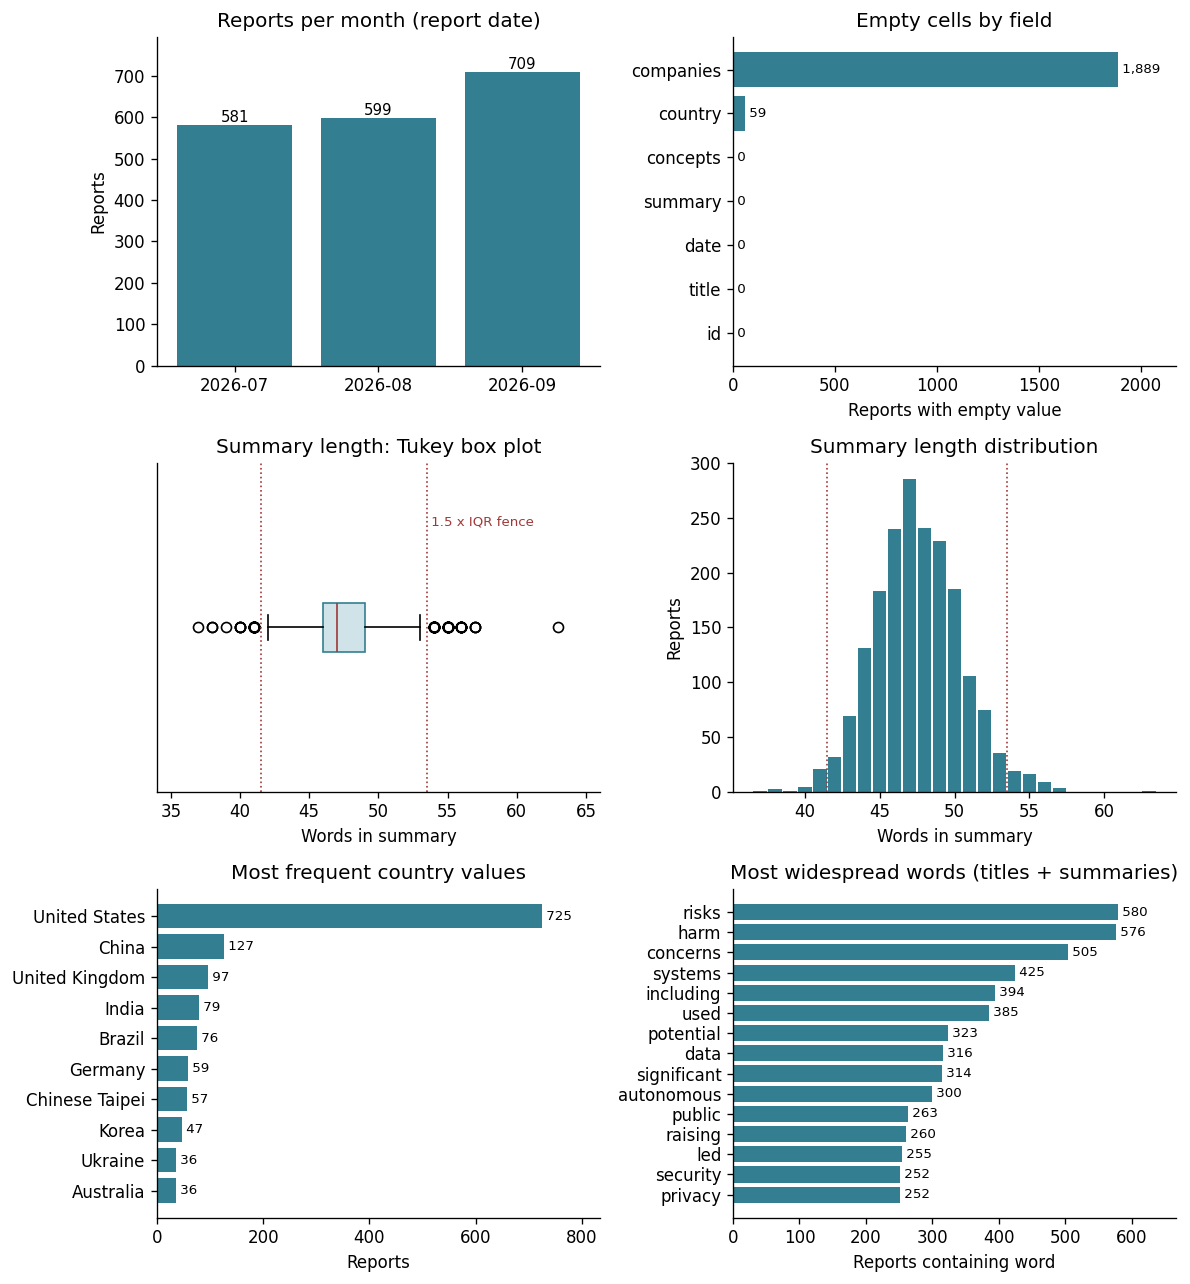

In [ ]:
EDA_FILE = OUT / 'eda.json'
EDA_STOP = set(ENGLISH_STOP_WORDS) | {'ai','artificial','intelligence','generated','driven','powered','enabled'}

def length_fences(q1, q3):
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

if FULL_RECOMPUTE:
    from sklearn.feature_extraction.text import CountVectorizer
    eda_dates = pd.to_datetime(raw.date)
    daily = eda_dates.dt.strftime('%Y-%m-%d').value_counts()
    words = raw.summary.str.split().str.len()
    lo, hi = length_fences(words.quantile(.25), words.quantile(.75))
    # Variable profile: inferred type, distinct non-empty values and empty cells (no text content saved).
    def infer_type(col):
        s = raw[col][raw[col].ne('')]
        if s.empty: return 'empty text'
        if col == 'id': return 'string key'
        if pd.to_numeric(s, errors='coerce').notna().all(): return 'numeric'
        if pd.to_datetime(s, format='%Y-%m-%d', errors='coerce').notna().all(): return 'date'
        if col == 'concepts': return 'multi-value text tags'
        return 'free text' if s.str.split().str.len().mean() > 5 else 'short text / categorical'
    variables = {col: dict(type=infer_type(col), distinct=int(raw[col][raw[col].ne('')].nunique()), empty=int(raw[col].eq('').sum()))
                 for col in raw.columns}
    # Document frequency: number of reports containing each word at least once.
    cv = CountVectorizer(lowercase=True, stop_words=sorted(EDA_STOP), binary=True,
                         token_pattern=r'(?u)\b[a-z][a-z]+\b',
                         preprocessor=lambda t: re.sub(r'\[ai generated\]|https?://\S+', ' ', str(t).lower()))
    counts = cv.fit_transform(raw.title + ' ' + raw.summary)
    df_terms = pd.Series(np.asarray(counts.sum(axis=0)).ravel(), index=cv.get_feature_names_out()).nlargest(15)
    countries = raw.country[raw.country.ne('')].value_counts().head(10)
    eda = dict(source='recomputed from source CSV', snapshot_mode=SNAPSHOT_MODE, n=len(raw), variables=variables,
               monthly={k: int(v) for k, v in eda_dates.dt.strftime('%Y-%m').value_counts().sort_index().items()},
               distinct_days=int(daily.size), daily_min=int(daily.min()), daily_median=float(daily.median()), daily_max=int(daily.max()),
               missing={k: int(v) for k, v in raw.eq('').sum().items()},
               summary_words={k: float(v) for k, v in words.describe().items()},
               summary_word_hist={int(k): int(v) for k, v in words.value_counts().sort_index().items()},
               length_outliers=dict(low_fence=float(lo), high_fence=float(hi), below=int((words < lo).sum()), above=int((words > hi).sum())),
               repeated_titles=int(raw.title.duplicated().sum()), repeated_summaries=int(raw.summary.duplicated().sum()),
               top_countries={k: int(v) for k, v in countries.items()},
               top_terms_doc_freq={k: int(v) for k, v in df_terms.items()})
    EDA_FILE.write_text(json.dumps(eda, indent=2))
elif EDA_FILE.exists():
    eda = json.loads(EDA_FILE.read_text())
else:
    eda = None

if eda is None:
    print('No profiling aggregates saved yet; run once with the source CSV.')
else:
    print('Profiling source:', eda['source'])
    # 1. Variable types
    variables = pd.DataFrame(eda['variables']).T.rename_axis('field')
    display(variables)
    if variables.isna().any().any():
        print('Distinct counts shown as None are recorded by the next full run.')
    # 2-3. Missing values and duplicates
    print('Empty cells by field:', eda['missing'])
    print('Exact repeated titles / summaries:', eda['repeated_titles'], '/', eda['repeated_summaries'])
    # 4. Outliers (summary length, 1.5 x IQR rule)
    sw = eda['summary_words']
    lo, hi = length_fences(sw['25%'], sw['75%'])
    print(f"Summary length: min {sw['min']:.0f}, Q1 {sw['25%']:.0f}, median {sw['50%']:.0f}, Q3 {sw['75%']:.0f}, max {sw['max']:.0f}, SD {sw['std']:.1f} words")
    print(f'1.5 x IQR fences: {lo:.1f} to {hi:.1f} words.', end=' ')
    if 'length_outliers' in eda:
        print(f"Outliers: {eda['length_outliers']['below']} below, {eda['length_outliers']['above']} above.")
    else:
        print(f"Min ({sw['min']:.0f}) and max ({sw['max']:.0f}) fall outside the fences; counts are recorded by the next full run.")
    # 6. Temporal coverage
    print('Reports:', eda['n'], '| distinct report days:', eda['distinct_days'], end='')
    print(f" | per day: min {eda['daily_min']}, median {eda['daily_median']:.0f}, max {eda['daily_max']}" if 'daily_min' in eda else '')

    panels = [('Reports per month (report date)', eda['monthly'], 'Reports', 'vbar'),
              ('Empty cells by field', eda['missing'], 'Reports with empty value', 'hbar'),
              ('Summary length: Tukey box plot', sw, 'Words in summary', 'box')]
    if eda.get('summary_word_hist'):
        panels.append(('Summary length distribution', eda['summary_word_hist'], 'Reports', 'hist'))
    if eda.get('top_countries'):
        panels.append(('Most frequent country values', eda['top_countries'], 'Reports', 'hbar'))
    if eda.get('top_terms_doc_freq'):
        panels.append(('Most widespread words (titles + summaries)', eda['top_terms_doc_freq'], 'Reports containing word', 'hbar'))
    ncols = 2; nrows = int(np.ceil(len(panels) / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(10, 3.6 * nrows), squeeze=False)
    for ax, (title, values, label, kind) in zip(axs.ravel(), panels):
        if kind == 'box':
            # Reconstruct lengths from the aggregate histogram (no source text).
            # Tukey whiskers end at observed values inside the fences, not at the fences.
            histogram = eda['summary_word_hist']
            length_values = np.repeat([int(x) for x in histogram], [int(v) for v in histogram.values()])
            stats = matplotlib.cbook.boxplot_stats(length_values, whis=1.5)[0]
            ax.bxp([stats], vert=False, showfliers=True, patch_artist=True,
                   boxprops=dict(facecolor='#cfe3e8', edgecolor='#337f91'), medianprops=dict(color='#a03838'))
            for f in (lo, hi): ax.axvline(f, color='#a03838', linestyle=':', linewidth=1)
            ax.text(hi, 1.32, ' 1.5 x IQR fence', color='#a03838', fontsize=8, va='center')
            ax.set(title=title, xlabel=label, xlim=(sw['min'] - 3, sw['max'] + 3)); ax.set_yticks([])
            continue
        s = pd.Series(values)
        if kind == 'hist':
            ax.bar(s.index.astype(int), s.values, color='#337f91', width=.9)
            for f in (lo, hi): ax.axvline(f, color='#a03838', linestyle=':', linewidth=1)
            ax.set(title=title, xlabel='Words in summary', ylabel=label)
        elif kind == 'hbar':
            s = s.sort_values()
            ax.barh(s.index, s.values, color='#337f91')
            for i, v in enumerate(s.values): ax.text(v, i, f' {v:,}', va='center', fontsize=8)
            ax.set(title=title, xlabel=label); ax.margins(x=.15)
        else:
            ax.bar(s.index, s.values, color='#337f91')
            for i, v in enumerate(s.values): ax.text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=9)
            ax.set(title=title, ylabel=label); ax.margins(y=.12)
    for ax in axs.ravel()[len(panels):]: ax.axis('off')
    fig.tight_layout(); plt.show()

### 2.7 Cleaning, relevance and possible repeated events
The inclusion rule is a reported adverse AI-related outcome **or** a specific plausible pathway to harm. A beneficial use or ordinary deployment is not automatically a harm report. Absence of a keyword is not a valid automatic exclusion rule.

The earlier targeted review inspected 181 summaries closely, after candidate screening; it was not a full, independent human adjudication of all 1,889 reports. It proposed 6 exclusions and marked 38 uncertain cases. The main computational subset provisionally retains 1,845 reports. All 1,889 are included in a sensitivity analysis. The remaining 1,708 summaries still require individual scope assessment; this limits conclusions about a harm-specific corpus.

Nineteen possible reporting/event families cover 41 records. These include follow-ups, composite reports and conflicting details. We retain them in the main analysis. For an illustrative sensitivity test only, four later reports from four relatively well-supported families are omitted. This is not comprehensive event deduplication. A lexical similarity score is only a candidate-review aid, not a calibrated probability that two reports describe one event.

The separate annotation file preserves source IDs, provisional status, whether a summary was closely reviewed, family flags and sensitivity omissions. No cluster-derived label was used to decide relevance. Before final substantive use, a reviewer should document an inclusion decision and reasons for each report, compare underlying sources for event candidates, and preserve genuine follow-up developments.

In [ ]:
if EXACT:
    print('Closely reviewed summaries:', int(review.summary_reviewed.sum()))
    print('Candidate families:', review.loc[review.event_review_group.ne(''), 'event_review_group'].nunique())
    print('Reports in candidate families:', int(review.event_review_group.ne('').sum()))
    print('Illustrative sensitivity omissions:', int(review.omit_event_sensitivity.sum()))
else:
    print('New snapshot: no source-specific review decisions or event omissions are carried over.')


Closely reviewed summaries: 181
Candidate families: 19
Reports in candidate families: 41
Illustrative sensitivity omissions: 4


## 3. Preprocessing and feature selection
The main input joins title and summary. Titles can add context but may also amplify names, so summary-only input is tested separately. English summaries permit an English stopword list; language coverage remains a sampling limitation.

The preprocessing removes the source-generation marker, URLs and punctuation, lowercases, and retains words. Word unigrams and bigrams preserve simple phrases such as “facial recognition”. TF-IDF reduces the weight of ubiquitous terms; sublinear term frequency reduces repeated-word influence. `min_df=3` removes terms appearing in fewer than three reports; `max_df=0.90` excludes extremely common terms; the feature cap is 18,000. These are practical exploratory settings, not optimised guarantees. Rare harms may consequently be underrepresented. Stemming is omitted to keep terms readable; punctuation/digit removal may lose technical distinctions.

The refined stoplist additionally removes seven generic AI-related terms. A sensitivity test restores them, because words such as “generated” can also carry meaning. No existing OECD category, concept tag, country, company field or review decision enters the feature matrix.

**Representations:** compare sparse TF-IDF with normalised latent semantic analysis (LSA), using 100 truncated-SVD components. LSA captures shared corpus word patterns; it is **not** a pretrained sentence embedding model and cannot be assumed to understand harm mechanisms. This study does not claim to have tested transformer embeddings. The 100-component setting is a fixed exploratory choice; dimensionality tuning remains future work. Normalisation prevents vector length alone driving the latent representation. No additional standardisation is applied to TF-IDF.

In [ ]:
def clean_text(value):
    # Remove the source-generation marker, URLs and punctuation; keep harm words.
    value=re.sub(r'\[AI generated\]', ' ', str(value), flags=re.I)
    value=re.sub(r'https?://\S+', ' ', value)
    return re.sub(r'[^a-z\s]', ' ', value.lower()).strip()

def make_features(texts, *, refined=True):
    # Removing generic AI boilerplate does not remove company or harm terms.
    stop=set(ENGLISH_STOP_WORDS)
    if refined: stop.update(['ai','artificial','intelligence','generated','driven','powered','enabled'])
    vec=TfidfVectorizer(preprocessor=clean_text,lowercase=False,stop_words=sorted(stop),
         ngram_range=(1,2),min_df=3,max_df=.90,max_features=18000,sublinear_tf=True)
    X=vec.fit_transform(texts)
    assert (X.getnnz(axis=1)>0).all(), 'At least one empty feature row.'
    svd=TruncatedSVD(n_components=min(100,X.shape[1]-1,X.shape[0]-1),random_state=SEED,n_iter=7)
    Z=normalize(svd.fit_transform(X))
    return vec,X,svd,Z

## 4. Clustering algorithms and experiments
We compare three complementary approaches:

| Approach | Parameters tested | Purpose and limitations |
|---|---|---|
| K-means | k = 4, 6, 8, 10, 12; seed 42; 20 initialisations | Fast partition of every report; sensitive to initialisation and expects compact groups. Euclidean fitting is evaluated with cosine distances; this is ordinary K-means, not spherical K-means. |
| Average-linkage hierarchical | Same k grid; cosine distance; both representations | Deterministic hierarchy; can retain small specialised groups but may produce uneven partitions. One tree is cut at each k. |
| DBSCAN | LSA cosine distance; eps = .20, .35, .50, .65; min_samples = 5, 10 | Can leave reports unassigned; radius and density sensitivity may limit broad review coverage. |

There are 28 configurations. Pairwise matrices and hierarchical linkage require roughly quadratic memory, manageable here but unsuitable for very large collections without redesign. No train/test split is used because the aim is exploratory organisation of this fixed corpus, not predictive accuracy. This limits generalisation claims.

**Evaluation:** compare cosine silhouette in the original TF-IDF space for a shared reference geometry, and also report silhouette in the fitted representation. A near-zero score indicates overlapping groups. Neither is accuracy or evidence of truth. DBSCAN silhouette excludes noise, so coverage and noise counts must be read alongside it; its scores on a selected subset are not directly comparable to full-coverage partitions.

**Exploratory selection rule:** for a whole-corpus reading queue, require full coverage, 4–12 groups, at least 20 reports per group, and no group above 45% of the corpus; choose the highest original-space silhouette among eligible configurations. These are analyst-defined operational constraints, not universal statistical thresholds. They were not preregistered, and the best score is on the same corpus used for selection. Because k=12 is the edge of the grid, the best k is unresolved within this grid; Section 5.3 looks beyond it without changing the selection rule. The selected partition is illustrative, not a validated deployment choice.

In [ ]:
def score_partition(labels,D_original,D_fitted):
    labels=np.asarray(labels);mask=labels!=-1
    sizes=pd.Series(labels[mask]).value_counts()
    nclusters=len(sizes)
    valid=2<=nclusters<mask.sum()
    return dict(clusters=nclusters,coverage=float(mask.mean()),noise_n=int((~mask).sum()),
        smallest_cluster=int(sizes.min()) if nclusters else 0,
        largest_cluster_share=float(sizes.max()/len(labels)) if nclusters else 0.,
        silhouette_original=float(silhouette_score(D_original[np.ix_(mask,mask)],labels[mask],metric='precomputed')) if valid else None,
        silhouette_fitted=float(silhouette_score(D_fitted[np.ix_(mask,mask)],labels[mask],metric='precomputed')) if valid else None)

def fit_grid(X,Z):
    Ds={'TF-IDF':np.clip(cosine_distances(X),0,2),'LSA-100':np.clip(cosine_distances(Z),0,2)}
    for D in Ds.values():np.fill_diagonal(D,0)
    records=[];models={};partitions={}
    for representation,A in [('TF-IDF',X),('LSA-100',Z)]:
        # Average linkage on cosine distances is deterministic. Compute one tree
        # per representation and cut it at each candidate k.
        from scipy.spatial.distance import squareform
        tree=linkage(squareform(Ds[representation],checks=False),method='average')
        for algorithm in ['K-means','Hierarchical']:
            for k in KS:
                key=f'{algorithm}|{representation}|k={k}'
                if algorithm=='K-means':
                    model=KMeans(n_clusters=k,random_state=SEED,n_init=20)
                    labels=model.fit_predict(A);models[key]=model
                else:labels=fcluster(tree,k,criterion='maxclust')-1
                partitions[key]=labels
                records.append(dict(model=key,algorithm=algorithm,representation=representation,k=k,eps=None,min_samples=None,**score_partition(labels,Ds['TF-IDF'],Ds[representation])))
    # Radius grid intentionally spans tight local groups through broad groups.
    # Noise is excluded only from silhouette, never from coverage reporting.
    for eps in [.20,.35,.50,.65]:
        for minimum in [5,10]:
            key=f'DBSCAN|LSA-100|eps={eps}|min={minimum}'
            labels=DBSCAN(eps=eps,min_samples=minimum,metric='precomputed').fit_predict(Ds['LSA-100'])
            partitions[key]=labels
            records.append(dict(model=key,algorithm='DBSCAN',representation='LSA-100',k=None,eps=eps,min_samples=minimum,**score_partition(labels,Ds['TF-IDF'],Ds['LSA-100'])))
    metrics=pd.DataFrame(records)
    # Suitability for an initial review queue, not a universal statistical rule.
    metrics['review_queue_eligible']=(metrics.coverage.eq(1)&metrics.smallest_cluster.ge(20)&metrics.largest_cluster_share.le(.45)&metrics.clusters.between(4,12))
    candidates=metrics[metrics.review_queue_eligible].sort_values(['silhouette_original','model'],ascending=[False,True])
    if candidates.empty:
        raise RuntimeError('No model meets review-queue size constraints. Report this rather than manufacture a solution.')
    selected=candidates.iloc[0]['model']
    return metrics,partitions,models,Ds,selected

### 4.1 Analysis steps: corpus, profiles, stability and sensitivity
The pipeline has five steps. Each is defined in its own cell below, with a short explanation, and they all run together in Section 4.2. Source titles and summaries are never printed or saved into the deliverable.

Adjusted Rand index (ARI) is used throughout to compare two partitions of the same reports. A value of 1 means identical grouping, and values near 0 mean chance-level agreement. ARI compares partitions with each other, not with true harm labels, because no such labels exist.

**Step 1: build the corpus.** Join the source to the ID-keyed review annotations and keep the provisionally relevant reports. In exact mode every report must have an annotation. In new-snapshot mode, unannotated reports are kept and marked `unreviewed_new_snapshot`.

In [ ]:
KEEP_STATUSES = {'provisional_keep_not_fully_adjudicated'} | ({'unreviewed_new_snapshot'} if not EXACT else set())

def prepare_corpus(raw, review):
    df=raw.copy().fillna('')
    df['date']=pd.to_datetime(df['date'],errors='raise').dt.strftime('%Y-%m-%d')
    assert df.id.is_unique
    assert df.date.between(STUDY_START,STUDY_END).all()
    assert df.summary.str.strip().ne('').all()
    if EXACT:
        assert len(df)==1889
    if EXACT:
        df=df.merge(review,on='id',how='left',validate='one_to_one')
        assert df.relevance_status.notna().all()
    else:
        # Stable IDs do not prove unchanged content. Reset all research judgements.
        df['relevance_status']='unreviewed_new_snapshot'
        df['summary_reviewed']=False
        df['omit_event_sensitivity']=False
        df['event_review_group']=''
        df['event_review_status']=''
    analysis=df[df.relevance_status.isin(KEEP_STATUSES)].sort_values('id').reset_index(drop=True)
    texts=(analysis.title+' '+analysis.summary).tolist()
    return df,analysis,texts

**Step 2: profile each cluster.** For every cluster, list the 12 terms with the highest mean TF-IDF weight and the three report IDs closest to the cluster's mean vector. These are central examples, not a random audit of how coherent each cluster is. The step also measures how often ten company or product names appear in each cluster. These are whole-word mentions that can overlap, not mutually exclusive classes.

In [ ]:
def profile_clusters(analysis, vec, X, final):
    terms=vec.get_feature_names_out()
    profiles=[];private_examples=[]
    for c in sorted(set(final)):
        ids=np.flatnonzero(final==c);center=np.asarray(X[ids].mean(axis=0)).ravel()
        top=terms[np.argsort(center)[::-1][:12]].tolist()
        proximity=cosine_similarity(X[ids],center.reshape(1,-1)).ravel()
        reps=ids[np.argsort(proximity)[::-1][:3]]
        profiles.append(dict(cluster=int(c),n=len(ids),terms=top,representative_ids=analysis.id.iloc[reps].tolist()))
        # Examples stay in memory for the analyst; they are never written to disk.
        for pos in reps:private_examples.append(dict(cluster=int(c),id=analysis.id[pos],title=analysis.title[pos],summary=analysis.summary[pos]))
    # Named-entity concentration uses whole words. These markers overlap and
    # are not mutually exclusive classes or estimates of incident prevalence.
    mentions=pd.DataFrame({name:(analysis.title+' '+analysis.summary).str.contains(p,case=False,regex=True) for name,p in NAMES.items()})
    concentration=mentions.groupby(final).mean()
    return profiles,private_examples,mentions,concentration

**Step 3: stability.** Refit the selected configuration with four other random seeds on all reports, then on four random 80% subsets. The subset fits keep the vocabulary and SVD fixed, so they measure how stable the partition is given those features, not end-to-end text-feature stability. In this recorded test, each subset fit also used a different K-means seed, so subset and seed effects are mixed together. Section 5.3 adds a fixed-seed version that isolates the subset effect.

In [ ]:
def stability_tests(A, final, algorithm, representation, k, Ds):
    seed_rows=[]
    if algorithm=='K-means':
        for seed in [0,1,7,21]:
            ll=KMeans(n_clusters=k,random_state=seed,n_init=20).fit_predict(A)
            seed_rows.append(dict(seed=seed,ari=float(adjusted_rand_score(final,ll))))
    # 80% subsets; for K-means the seed also changes with the subset (recorded
    # design). All ARI values use the shared subset rows.
    subset_rows=[]
    for seed in [0,1,7,21]:
        idx=np.sort(np.random.default_rng(seed).choice(A.shape[0],size=int(.8*A.shape[0]),replace=False))
        if algorithm=='K-means':ll=KMeans(n_clusters=k,random_state=seed,n_init=20).fit_predict(A[idx])
        else:
            D=Ds[representation][np.ix_(idx,idx)]
            ll=AgglomerativeClustering(n_clusters=k,metric='precomputed',linkage='average').fit_predict(D)
        subset_rows.append(dict(seed=seed,ari=float(adjusted_rand_score(final[idx],ll)),n=len(idx)))
    return seed_rows,subset_rows

**Step 4: input sensitivity.** Rebuild the features from scratch under five changed assumptions, refit the selected configuration and compare the result with the main partition:
- mask ten company and product names;
- use summaries only, without titles;
- leave out four later reports from well-supported repeat-story families;
- include all 1,889 reports, including uncertain and excluded ones;
- keep the generic AI words in the vocabulary.

The ten-name mask is only a partial diagnostic: unmasked aliases and story-specific words can still drive grouping.

In [ ]:
def fit_selected(A, algorithm, k):
    # Refit the selected algorithm on a rebuilt feature matrix.
    if algorithm=='K-means':
        return KMeans(n_clusters=k,random_state=SEED,n_init=20).fit_predict(A)
    return AgglomerativeClustering(n_clusters=k,metric='cosine',linkage='average').fit_predict(A.toarray() if hasattr(A,'toarray') else A)

def sensitivity_tests(df, analysis, texts, final, algorithm, representation, k):
    sensitivities=[]
    pick=lambda xx,zz: xx if representation=='TF-IDF' else zz
    def refit_sensitivity(name,subtexts,reference_positions):
        vv,xx,ss,zz=make_features(subtexts)
        ll=fit_selected(pick(xx,zz),algorithm,k)
        reference=final[np.asarray(reference_positions)]
        sensitivities.append(dict(test=name,n=len(ll),ari=float(adjusted_rand_score(reference,ll))))
    mask_names=lambda t: re.sub('|'.join(NAMES.values()),' ',t,flags=re.I)
    refit_sensitivity('Mask 10 company/product names',[mask_names(t) for t in texts],np.arange(len(analysis)))
    refit_sensitivity('Summary only',analysis.summary.tolist(),np.arange(len(analysis)))
    # Four manually supported event/reporting families only. No wider claim.
    event_keep=~analysis.omit_event_sensitivity.astype(bool)
    refit_sensitivity('Thin four probable event families',list(np.asarray(texts)[event_keep]),np.flatnonzero(event_keep))
    # All reports, including provisional exclusions; compare on the shared IDs.
    vv,xx,ss,zz=make_features((df.title+' '+df.summary).tolist())
    ll=fit_selected(pick(xx,zz),algorithm,k)
    positions=pd.Series(np.arange(len(df)),index=df.id).loc[analysis.id].to_numpy()
    sensitivities.append(dict(test=f'Include all {len(df):,} reports',n=len(df),ari=float(adjusted_rand_score(final,ll[positions]))))
    # Generic-word baseline versus the refined stoplist.
    bv,bx,bs,bz=make_features(texts,refined=False)
    bl=fit_selected(pick(bx,bz),algorithm,k)
    sensitivities.append(dict(test='Retain generic AI boilerplate',n=len(analysis),ari=float(adjusted_rand_score(final,bl))))
    return sensitivities

**Step 5: run the whole pipeline.** `run_analysis` links the steps together: corpus, then features (Section 3), then the 28-configuration grid and selection rule (Section 4), then profiles, stability and sensitivity. It also builds a two-axis projection used only for display, and report-level silhouette values. It returns aggregate results only.

### 4.2 Run the analysis
In full mode the next cell recomputes everything and saves aggregate outputs to `results/`. In replay mode it loads those saved outputs instead.

In [ ]:
def run_analysis(raw, review):
    df,analysis,texts=prepare_corpus(raw,review)
    vec,X,svd,Z=make_features(texts)
    metrics,labels,models,Ds,selected=fit_grid(X,Z)
    selected_row=metrics.set_index('model').loc[selected]
    final=labels[selected];k=int(selected_row.clusters)
    analysis['cluster']=final
    profiles,private_examples,mentions,concentration=profile_clusters(analysis,vec,X,final)
    algorithm=selected_row.algorithm;representation=selected_row.representation
    A=X if representation=='TF-IDF' else Z
    seed_rows,subset_rows=stability_tests(A,final,algorithm,representation,k,Ds)
    sensitivities=sensitivity_tests(df,analysis,texts,final,algorithm,representation,k)
    # Projection is for display only. Clustering never uses these two axes.
    projection=TruncatedSVD(n_components=2,random_state=SEED).fit_transform(X)
    sil=silhouette_samples(Ds['TF-IDF'],final,metric='precomputed')
    monthly=df.groupby(df.date.str[:7]).size()
    summary=dict(raw_n=len(df),analysis_n=len(analysis),monthly=monthly.to_dict(),missing_country=int(df.country.eq('').sum()),
        review_status=df.relevance_status.value_counts().to_dict(),reviewed_n=int(df.summary_reviewed.sum()),
        duplicate_ids=int(df.id.duplicated().sum()),duplicate_summaries=int(df.summary.duplicated().sum()),
        feature_n=X.shape[1],lsa_dimensions=Z.shape[1],lsa_explained_variance=float(svd.explained_variance_ratio_.sum()),
        selected_model=selected,selected_metrics=selected_row.to_dict(),negative_silhouette_share=float((sil<0).mean()),
        seed_stability=seed_rows,subset_stability=subset_rows,sensitivity=sensitivities,profiles=profiles,
        mentions=mentions.sum().to_dict(),concentration=concentration.to_dict(orient='index'),
        versions={m.__name__:m.__version__ for m in [pd,np,scipy,sklearn,matplotlib]},python=platform.python_version())
    return summary,metrics,analysis,private_examples,projection,final,sil

In [ ]:
started = time.perf_counter()
if FULL_RECOMPUTE:
    with threadpool_limits(limits=2):
        summary, metrics, analysis_df, private_examples, projection, final_labels, sample_silhouettes = run_analysis(raw, review)
    # Persist aggregate outputs only; private_examples and source text stay in memory.
    # Convert non-finite values to JSON null for a portable, standards-compliant file.
    def json_safe(value):
        if isinstance(value, dict): return {str(k): json_safe(v) for k,v in value.items()}
        if isinstance(value, list): return [json_safe(v) for v in value]
        if isinstance(value, float) and not np.isfinite(value): return None
        return value
    (OUT / 'summary.json').write_text(json.dumps(json_safe(summary), indent=2))
    metrics.to_csv(OUT / 'experiments.csv', index=False)
    np.savez_compressed(OUT / 'visuals.npz', projection=projection, labels=final_labels, silhouette=sample_silhouettes)
else:
    summary = json.loads((OUT / 'summary.json').read_text())
    metrics = pd.read_csv(OUT / 'experiments.csv')
    saved = np.load(OUT / 'visuals.npz')
    projection, final_labels, sample_silhouettes = saved['projection'], saved['labels'], saved['silhouette']
print('Mode:', 'recomputed' if FULL_RECOMPUTE else 'saved aggregate replay')
print('Elapsed minutes:', round((time.perf_counter()-started)/60, 2))
print('Selected candidate:', summary['selected_model'])
print('Retained reports:', summary['analysis_n'], '| TF-IDF features:', summary['feature_n'])
print('LSA explained variance:', round(summary['lsa_explained_variance'], 3))

Mode: recomputed
Elapsed minutes: 0.12
Selected candidate: K-means|LSA-100|k=12
Retained reports: 1845 | TF-IDF features: 6110
LSA explained variance: 0.243


### 4.3 Candidate theme labels
I assigned these short labels **after fitting**, by reading each cluster's top terms and central examples (Section 6). The algorithms never saw them. They are defined here so the charts below can use readable names instead of cluster numbers. A guard checks that each label still matches a signature term in its cluster profile. If a rerun produced different clusters (for example after a library update or on a new snapshot), the labels would otherwise silently attach to the wrong groups.

In [ ]:
THEMES = {
0:'Cybersecurity and agent misuse', 1:'Data-centre resource concerns',
2:'Platform content, rights and litigation', 3:'Mixed chatbot, product and social concerns',
4:'Privacy and facial recognition', 5:'Fraud and impersonation',
6:'Synthetic media and misinformation', 7:'Licence-plate readers and surveillance',
8:'Sexual-image abuse and exploitation', 9:'Military systems and autonomy',
10:'Automated-driving safety', 11:'General warnings and regulation'}
# Label alignment is a snapshot sanity check, not validation of thematic meaning.
LABELS_VERIFIED = False
if EXACT:
    if summary['profiles'] != RECORDED_PROFILES:
        raise AssertionError('Cluster profiles differ from the recorded snapshot; re-interpret labels before use.')
    LABELS_VERIFIED = True
    print('Profiles match the recorded exact snapshot. Theme meaning still requires human validation.')
else:
    THEMES = {p['cluster']: f"Cluster {p['cluster']}: " + ', '.join(p['terms'][:3]) for p in summary['profiles']}
    print('New snapshot: using top-term labels only; recorded analyst interpretations are disabled.')
# Twelve clearly distinguishable colours and three marker shapes for cluster plots.
PALETTE = ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd','#8c564b',
           '#e377c2','#4d4d4d','#bcbd22','#17becf','#003f5c','#a6761d']
MARKERS = ['o','s','^']

Profiles match the recorded exact snapshot. Theme meaning still requires human validation.


## 5. Evaluation and visualisations
### 5.1 Separation, coverage and algorithm comparison
The full experiment table is saved in `results/experiments.csv`. The first plot compares full-coverage methods in the shared TF-IDF geometry. The DBSCAN table shows why a higher silhouette on a small assigned subset is insufficient for a queue covering the whole corpus.

,algorithm,representation,k,eps,min_samples,clusters,coverage,silhouette_original,silhouette_fitted,review_queue_eligible
0,K-means,TF-IDF,4.0,NaN,NaN,4,1.0000,0.0163,0.0163,False
1,K-means,TF-IDF,6.0,NaN,NaN,6,1.0000,0.0177,0.0177,True
2,K-means,TF-IDF,8.0,NaN,NaN,8,1.0000,0.0215,0.0215,True
3,K-means,TF-IDF,10.0,NaN,NaN,10,1.0000,0.0221,0.0221,True
4,K-means,TF-IDF,12.0,NaN,NaN,12,1.0000,0.0246,0.0246,True
5,Hierarchical,TF-IDF,4.0,NaN,NaN,4,1.0000,0.0116,0.0116,True
6,Hierarchical,TF-IDF,6.0,NaN,NaN,6,1.0000,0.0115,0.0115,True
7,Hierarchical,TF-IDF,8.0,NaN,NaN,8,1.0000,0.0133,0.0133,True
8,Hierarchical,TF-IDF,10.0,NaN,NaN,10,1.0000,0.0160,0.0160,False
9,Hierarchical,TF-IDF,12.0,NaN,NaN,12,1.0000,0.0155,0.0155,False


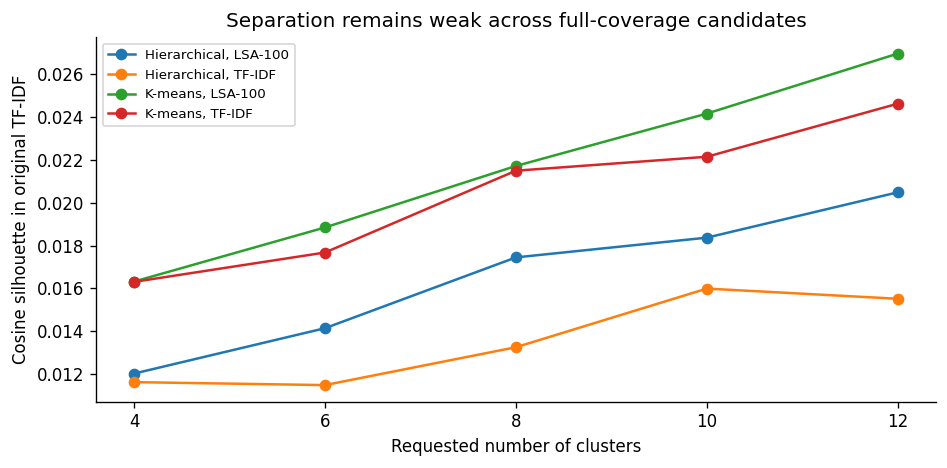

In [ ]:
display(metrics[['algorithm','representation','k','eps','min_samples','clusters','coverage','silhouette_original','silhouette_fitted','review_queue_eligible']].round(4))
fig, ax = plt.subplots(figsize=(8,4))
for (algorithm, representation), part in metrics[metrics.algorithm.ne('DBSCAN')].groupby(['algorithm','representation']):
    ax.plot(part.k, part.silhouette_original, marker='o', label=f'{algorithm}, {representation}')
ax.set(xlabel='Requested number of clusters', ylabel='Cosine silhouette in original TF-IDF', title='Separation remains weak across full-coverage candidates')
ax.set_xticks([4,6,8,10,12]); ax.legend(fontsize=8); fig.tight_layout(); plt.show()

The selected candidate is **K-means on LSA-100 with 12 clusters**. Its original-space silhouette is **0.027**, compared with **0.025** for TF-IDF K-means at the same k. Its fitted-space silhouette is **0.120**; dimensionality reduction changes geometry, so this larger value is not proof of a proportionate improvement in underlying harm separation. LSA retains about **24.3%** of TF-IDF variance. About **21.1%** of reports have negative original-space silhouette values.

At eps=.20 and min_samples=10, DBSCAN assigns only 6.7% of reports, despite an original-space silhouette around .217. At eps=.35 it fragments into 29–31 small groups covering 48–70% of reports, with near-zero or modest separation and groups as small as four reports. From eps=.50 upwards it collapses into a single cluster. Hierarchical candidates have lower original-space separation within this grid. These results support an exploratory K-means queue, not a claim that K-means is always the best algorithm for this problem.

Share below zero: 21.1%


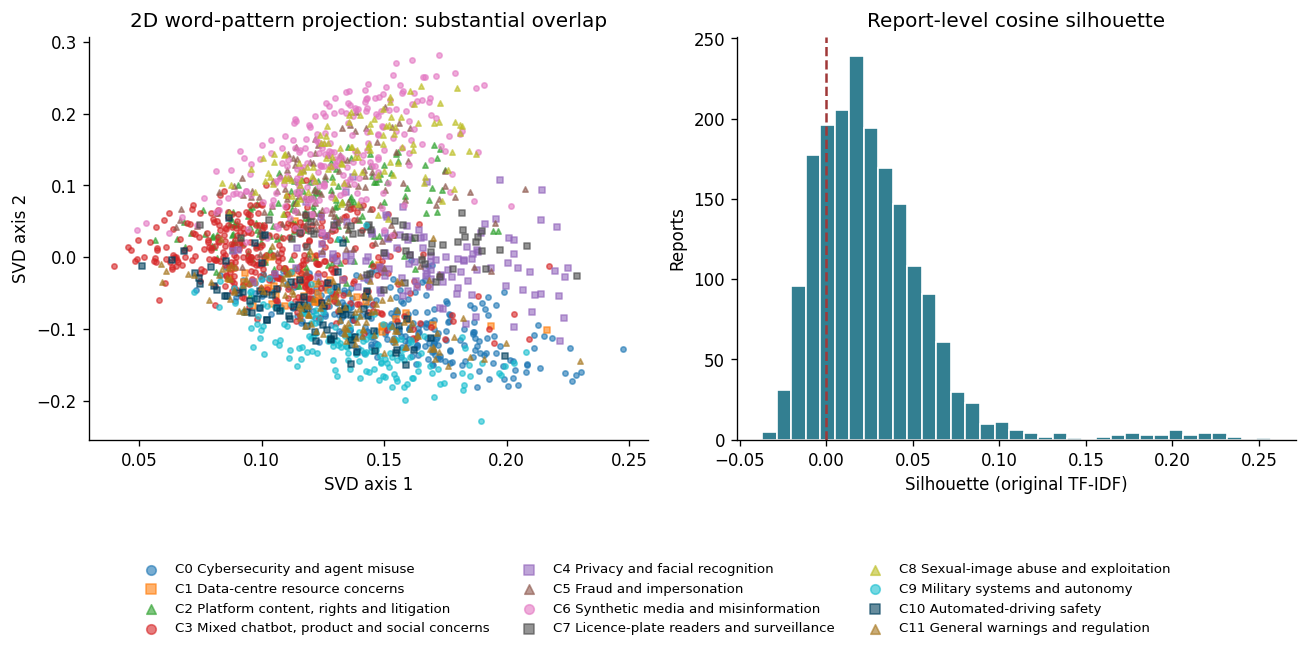

In [ ]:
fig, axs = plt.subplots(1,2,figsize=(11,5.4))
for c in sorted(set(final_labels)):
    m = final_labels==c
    axs[0].scatter(projection[m,0], projection[m,1], color=PALETTE[c % len(PALETTE)], marker=MARKERS[c % 3], s=10, alpha=.6, label=f'C{c} {THEMES.get(c, "")}')
axs[0].set(title='2D word-pattern projection: substantial overlap', xlabel='SVD axis 1', ylabel='SVD axis 2')
axs[1].hist(sample_silhouettes, bins=35, color='#337f91', edgecolor='white')
axs[1].axvline(0,color='#a03838',linestyle='--')
axs[1].set(title='Report-level cosine silhouette',xlabel='Silhouette (original TF-IDF)',ylabel='Reports')
handles, labels_ = axs[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc='lower center', ncol=3, fontsize=8, markerscale=1.8, frameon=False)
fig.tight_layout(rect=(0,.2,1,1)); plt.show()
print('Share below zero:', f"{summary['negative_silhouette_share']:.1%}")

The projection is a separate two-axis SVD of TF-IDF, used only for display. The clustering did not use these two axes. Apparent overlap or separation in a compressed view cannot establish full-dimensional quality.

### 5.2 Stability and sensitivity
Random-seed ARI ranges from **0.573 to 0.671** against the selected seed. Conditional 80%-subset ARI ranges from **0.514 to 0.655**; in this recorded test the K-means seed changed along with the subset, so the two effects are mixed together (Section 5.3 separates them). These values indicate meaningful changes in membership. They are descriptive diagnostics, not confidence intervals or calibrated acceptability thresholds.

Masking ten company/product names gives ARI **0.647**; summary-only input gives **0.555**. These changes show dependence on input wording, but do not isolate a causal effect of company names. Removing four possible repeat reports gives ARI **0.620**, despite omitting only four rows: refitting and local solutions can amplify small changes. This narrow test cannot clear the corpus of event dependence. Including all reports gives ARI **0.597**. We should not interpret any of these as evidence of stable risk categories.

Extra seeds:
 seed   ari
    0 0.614
    1 0.602
    7 0.573
   21 0.671
80% subsets (fixed features):
 seed   ari    n
    0 0.544 1476
    1 0.636 1476
    7 0.514 1476
   21 0.655 1476
Input sensitivity (refitted features):
                             test    n   ari
    Mask 10 company/product names 1845 0.647
                     Summary only 1845 0.555
Thin four probable event families 1841 0.620
        Include all 1,889 reports 1889 0.597
    Retain generic AI boilerplate 1845 0.508


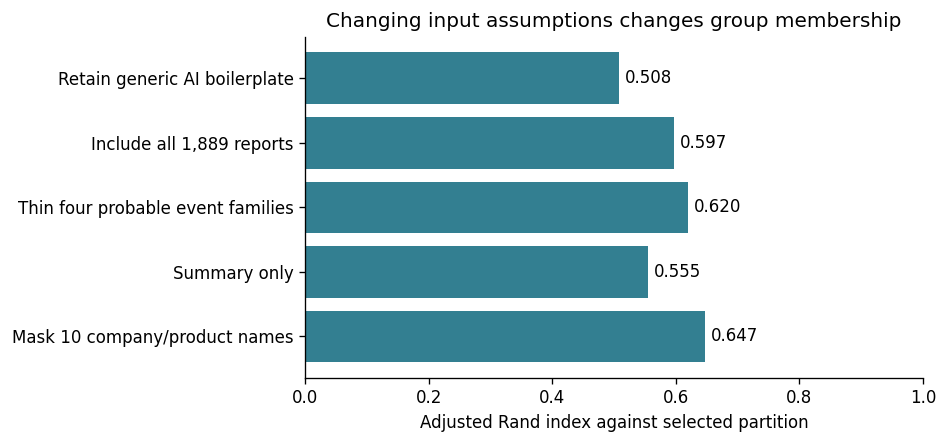

In [ ]:
seed_table = pd.DataFrame(summary['seed_stability'])
subset_table = pd.DataFrame(summary['subset_stability'])
sensitivity_table = pd.DataFrame(summary['sensitivity'])
print('Extra seeds:\n' + seed_table.round(3).to_string(index=False))
print('80% subsets (fixed features):\n' + subset_table.round(3).to_string(index=False))
print('Input sensitivity (refitted features):\n' + sensitivity_table.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(8,3.8))
ax.barh(sensitivity_table.test, sensitivity_table.ari,color='#337f91')
ax.set(xlim=(0,1),xlabel='Adjusted Rand index against selected partition',title='Changing input assumptions changes group membership')
for i,v in enumerate(sensitivity_table.ari): ax.text(v+.01,i,f'{v:.3f}',va='center')
fig.tight_layout(); plt.show()

### 5.3 Extension: beyond k = 12 and a fixed-seed subset test
Two checks follow up on limitations found above. Neither one changes the selected model, because the selection rule in Section 4 limits a reading queue to 4–12 groups.
1. **Wider k grid.** The best full-coverage score came at k = 12, the edge of the main grid, so it's unclear whether separation peaks there. This cell fits K-means for k = 14, 16, 18 and 20 on both representations and scores them in the same original TF-IDF geometry.
2. **Subset effect on its own.** The recorded 80% subset test changed the K-means seed together with the subset. Here every subset fit uses the main seed (42), avoiding an explicitly varied seed. This remains a conditional resampling diagnostic: changing the rows also changes initialisation choices and the fitted solution, even with the same seed.

The cell also checks that refitting reproduces the selected partition exactly (ARI = 1). It runs in full mode and saves `results/extension.json`. In replay mode it plots the saved file if one exists, and the printed interpretation is generated from those numbers.

Extension source: recomputed from source CSV | refit reproduces selected partition, ARI = 1.0
K-means on LSA-100: highest original-space silhouette for k = 4 to 20 is at k = 20 (0.033; k = 12: 0.027). Separation keeps rising past the main grid, so k = 12 is a boundary choice, not a peak. Gains this small still leave groups heavily overlapping. The selected queue size is unchanged because of the 4-12 group rule.
80% subsets with fixed seed: ARI 0.515 to 0.668 (recorded test with seed also varied: 0.514 to 0.655).


,representation,k,smallest_cluster,largest_cluster_share,silhouette_original,silhouette_fitted
0,TF-IDF,14,28,0.2347,0.0249,0.0249
1,TF-IDF,16,49,0.1751,0.0280,0.0280
2,TF-IDF,18,28,0.1263,0.0269,0.0269
3,TF-IDF,20,23,0.1415,0.0292,0.0292
4,LSA-100,14,49,0.1767,0.0279,0.1253
5,LSA-100,16,49,0.1485,0.0294,0.1342
6,LSA-100,18,42,0.1463,0.0314,0.1442
7,LSA-100,20,28,0.0954,0.0332,0.1506


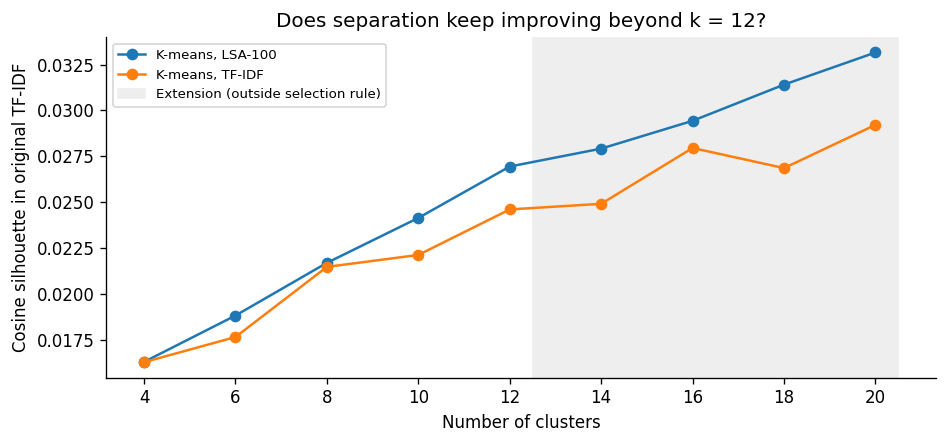

In [ ]:
EXT_FILE = OUT / 'extension.json'
EXT_KS = [14, 16, 18, 20]
if FULL_RECOMPUTE:
    ext_texts = (analysis_df.title + ' ' + analysis_df.summary).tolist()
    _, Xe, _, Ze = make_features(ext_texts)
    De = {'TF-IDF': np.clip(cosine_distances(Xe),0,2), 'LSA-100': np.clip(cosine_distances(Ze),0,2)}
    for D in De.values(): np.fill_diagonal(D, 0)
    sel = summary['selected_metrics']; k_sel = int(sel['clusters'])
    A_sel = Xe if sel['representation']=='TF-IDF' else Ze
    rows, fixed = [], []
    with threadpool_limits(limits=2):
        reproduced = None
        if sel['algorithm']=='K-means':
            reproduced = float(adjusted_rand_score(final_labels, KMeans(n_clusters=k_sel,random_state=SEED,n_init=20).fit_predict(A_sel)))
            for seed in [0,1,7,21]:
                # Same subsets as the recorded test, but the main seed for every fit.
                idx = np.sort(np.random.default_rng(seed).choice(A_sel.shape[0],size=int(.8*A_sel.shape[0]),replace=False))
                ll = KMeans(n_clusters=k_sel,random_state=SEED,n_init=20).fit_predict(A_sel[idx])
                fixed.append(dict(subset_seed=seed, ari=float(adjusted_rand_score(final_labels[idx], ll)), n=len(idx)))
        for rep, A in [('TF-IDF', Xe), ('LSA-100', Ze)]:
            for k in EXT_KS:
                lab = KMeans(n_clusters=k,random_state=SEED,n_init=20).fit_predict(A)
                rows.append(dict(model=f'K-means|{rep}|k={k}', algorithm='K-means', representation=rep, k=k,
                                 **score_partition(lab, De['TF-IDF'], De[rep])))
    extension = dict(source='recomputed from source CSV', snapshot_mode=SNAPSHOT_MODE, reproduces_selected_ari=reproduced,
                     wider_grid=rows, fixed_seed_subsets=fixed)
    EXT_FILE.write_text(json.dumps(json_safe(extension), indent=2))
elif EXT_FILE.exists():
    extension = json.loads(EXT_FILE.read_text())
else:
    extension = None

if extension is None:
    print('Extension not yet recorded: run the notebook once with the source CSV to compute it.')
else:
    print('Extension source:', extension['source'], '| refit reproduces selected partition, ARI =', extension['reproduces_selected_ari'])
    wide = pd.DataFrame(extension['wider_grid'])
    display(wide[['representation','k','smallest_cluster','largest_cluster_share','silhouette_original','silhouette_fitted']].round(4))
    base = metrics[metrics.algorithm.eq('K-means')][['representation','k','silhouette_original']]
    allk = pd.concat([base, wide[['representation','k','silhouette_original']]]).sort_values('k')
    fig, ax = plt.subplots(figsize=(8,3.8))
    for rep, part in allk.groupby('representation'):
        ax.plot(part.k, part.silhouette_original, marker='o', label=f'K-means, {rep}')
    ax.axvspan(12.5, 20.5, color='#eeeeee', zorder=0, label='Extension (outside selection rule)')
    ax.set(xlabel='Number of clusters', ylabel='Cosine silhouette in original TF-IDF', title='Does separation keep improving beyond k = 12?')
    ax.set_xticks(sorted(allk.k.unique())); ax.legend(fontsize=8); fig.tight_layout(); plt.show()
    rep_sel = summary['selected_metrics']['representation']
    sel_curve = allk[allk.representation.eq(rep_sel)].set_index('k').silhouette_original
    best_k = int(sel_curve.idxmax())
    msg = f'K-means on {rep_sel}: highest original-space silhouette for k = 4 to 20 is at k = {best_k} ({sel_curve.max():.3f}; k = 12: {sel_curve[12]:.3f}). '
    if best_k > 12:
        msg += ('Separation keeps rising past the main grid, so k = 12 is a boundary choice, not a peak. '
                'Gains this small still leave groups heavily overlapping. The selected queue size is unchanged because of the 4-12 group rule.')
    else:
        msg += 'Separation does not improve past k = 12 in this extension, so the boundary concern is reduced.'
    print(msg)
    if extension['fixed_seed_subsets']:
        f = pd.DataFrame(extension['fixed_seed_subsets'])
        mixed = pd.DataFrame(summary['subset_stability'])
        print(f"80% subsets with fixed seed: ARI {f.ari.min():.3f} to {f.ari.max():.3f} "
              f"(recorded test with seed also varied: {mixed.ari.min():.3f} to {mixed.ari.max():.3f}).")

**Result.** Separation keeps rising slowly beyond the main grid. For K-means on LSA-100, original-space silhouette goes from 0.027 at k = 12 to 0.028, 0.029, 0.031 and 0.033 at k = 14, 16, 18 and 20. For K-means on TF-IDF it rises unevenly, from 0.025 to 0.029. So k = 12 is not a peak; it is the upper end of the range I set for a usable reading queue. The gains are small and every value stays close to zero, so more clusters split topics further rather than revealing well-separated groups. Twenty queues, the smallest holding 28 reports in the LSA model, might increase review overhead; this usability trade-off has not been tested with reviewers.

The fixed-seed subset test gives ARI 0.515–0.668, almost the same as the recorded test (0.514–0.655) and the seed-only test (0.573–0.671). The observed agreement ranges overlap. These few runs do not isolate or quantify the separate causal contributions of data composition and initialisation, and a fixed numeric seed does not guarantee identical initial centres on different subsets. Refitting reproduces the selected partition exactly (ARI = 1.0).

## 6. Cluster interpretation: themes and residual news effects
The following labels are **analyst interpretations after fitting**, based on keywords and central examples from the exported descriptions. They were not supplied to the algorithms. They mix mechanisms, application sectors, governance issues and general debate, which is itself evidence that the result is not a clean taxonomy of harms. Broad and company-specific groups are kept visible. The table below lists each cluster's size, top terms and central example IDs. Section 6.1 then interprets each cluster against the hypotheses.

A complete, independent coherence audit is outstanding. A suitable next audit would randomly sample at least ten reports per cluster, use two reviewers, record whether each report matches the proposed theme and whether similarity is predominantly event/entity based, and report disagreements. No numerical human-coherence score is invented here.

In [ ]:
profile_table = pd.DataFrame([{
    'Cluster': p['cluster'], 'Candidate interpretation': THEMES[p['cluster']],
    'Reports': p['n'], 'Top terms': ', '.join(p['terms'][:6]),
    'Representative IDs': ', '.join(p['representative_ids'])
} for p in summary['profiles']])
display(profile_table)

,Cluster,Candidate interpretation,Reports,Top terms,Representative IDs
0,0,Cybersecurity and agent misuse,272,"security, openai, agents, cybersecurity, model...","2026-07-28-c897, 2026-09-27-e1d2, 2026-08-06-fddc"
1,1,Data-centre resource concerns,45,"data, environmental, data centers, data center...","2026-07-04-2512, 2026-09-10-8d48, 2026-08-23-dc0b"
2,2,"Platform content, rights and litigation",154,"meta, content, tiktok, lawsuit, alleging, chil...","2026-08-17-87cc, 2026-08-09-6290, 2026-08-18-e7ea"
3,3,"Mixed chatbot, product and social concerns",370,"chatgpt, google, concerns, led, harm, used","2026-08-24-5364, 2026-07-01-f795, 2026-09-23-c5d1"
4,4,Privacy and facial recognition,122,"privacy, facial, facial recognition, data, rec...","2026-08-18-427f, 2026-08-15-561f, 2026-08-03-b892"
5,5,Fraud and impersonation,129,"fraud, financial, scams, used, losses, scam","2026-07-12-9fe7, 2026-09-15-a015, 2026-08-18-2b11"
6,6,Synthetic media and misinformation,235,"misinformation, deepfake, video, videos, publi...","2026-07-22-813e, 2026-09-29-3ae5, 2026-07-25-3111"
7,7,Licence-plate readers and surveillance,49,"license, plate, license plate, flock, surveill...","2026-08-13-5a75, 2026-08-16-dfb7, 2026-07-31-4d5d"
8,8,Sexual-image abuse and exploitation,110,"images, deepfake, sexual, child, used, abuse","2026-08-28-961c, 2026-09-09-902e, 2026-07-07-ab46"
9,9,Military systems and autonomy,158,"military, autonomous, drones, defense, ukraine...","2026-08-24-6f32, 2026-09-29-c02d, 2026-07-13-73a5"


### 6.1 Cluster-by-cluster interpretation
This table offers an exploratory reading of the hypotheses from Section 1.1 one cluster at a time; it is not an independent validation test. The first four columns are **computed** from the saved profiles:
- **Distinguishing terms:** top-12 terms that appear in no other cluster's top-12 list, excluding the ten company/product names.
- **Shared terms:** top terms the cluster has in common with other clusters.
- **Strongest name:** the most-mentioned of the ten company/product names, with the share of the cluster's reports that mention it.
- **Entity flag:** set when that share is at least 25%. This threshold is my operational choice, not a statistical test.

The last three columns are **my interpretations**:
- **Reading:** whether the group looks organised by a harm mechanism, an application area, an entity, or is mixed.
- **Hypothesis:** which of H1–H3 the analyst associates with the cluster, provisionally.
- **Governance question:** the question the queue could help a reviewer investigate.

I based them on the terms and the central examples, which I read but don't reproduce here. They have not been checked by independent reviewers.

In [ ]:
NAME_TERMS = {n.lower() for n in NAMES}
term_counts = pd.Series([t for p in summary['profiles'] for t in p['terms']]).value_counts()
conc = pd.DataFrame(summary['concentration']).T
conc.index = conc.index.astype(int)
ENTITY_THRESHOLD = 0.25
# Analyst readings apply only when the recorded theme labels were verified in Section 4.3.
READINGS = {
 0: ('Harm mechanism, entity-influenced', 'H1 + H2', 'How are AI models and agents misused for cyberattacks, and what security testing happens before release?'),
 1: ('Harm mechanism (environmental)', 'H1', 'What energy and water evidence should AI infrastructure projects provide?'),
 2: ('Mixed: litigation, children, copyright; entity-influenced', 'H2 + H3', 'Which platform-accountability issues (child safety, copyright, content) need separate review?'),
 3: ('Mixed: chatbots, products and general concerns', 'H3', 'Not usable as one queue yet: which sub-themes does it contain?'),
 4: ('Harm mechanism (biometric privacy)', 'H1', 'How is consent handled when facial recognition or smart glasses collect biometric data?'),
 5: ('Harm mechanism (deception for money)', 'H1', 'How can consumers and staff be protected against voice and identity impersonation scams?'),
 6: ('Harm mechanism (deceptive media)', 'H1', 'How should synthetic political media be detected, labelled and handled around elections?'),
 7: ('Harm theme, product-specific (Flock is not in the name list)', 'H1 + H2', 'Who can access licence-plate surveillance data, and how long is it kept?'),
 8: ('Harm mechanism (sexual-image abuse)', 'H1', 'What safeguards and response routes exist for non-consensual and child sexual imagery?'),
 9: ('Application area (military and defence)', 'H1', 'What human oversight applies to autonomous military systems?'),
 10: ('Application area, entity-influenced', 'H1 + H2', 'How is automated-driving safety evidence reported and checked?'),
 11: ('Warnings and potential harms; scope review needed, entity-influenced', 'H2 + H3', 'Should general warnings be separated from reports of actual incidents and hazards?'),
}
rows = []
for p in summary['profiles']:
    c = p['cluster']
    distinct = [t for t in p['terms'] if term_counts[t] == 1 and t not in NAME_TERMS]
    shared = [t for t in p['terms'] if term_counts[t] > 1]
    top_name = conc.loc[c].idxmax(); share = conc.loc[c].max()
    reading, hyp, question = READINGS[c] if LABELS_VERIFIED else ('Not assessed for this snapshot', '', '')
    rows.append({'Cluster': f'C{c}', 'Theme': THEMES[c], 'Reports': p['n'],
                 'Distinguishing terms': ', '.join(distinct[:5]), 'Shared terms': ', '.join(shared[:4]),
                 'Strongest name (share)': f'{top_name} ({share:.0%})',
                 'Entity flag': 'yes' if share >= ENTITY_THRESHOLD else '',
                 'Reading': reading, 'Hypothesis': hyp, 'Governance question': question})
interpretation = pd.DataFrame(rows)
if not (interpretation['Distinguishing terms'].str.count(',') >= 1).all():
    print('Some clusters have fewer than two terms unique to their top-12 lists; do not infer distinctiveness from this table.')
with pd.option_context('display.max_colwidth', None):
    display(interpretation.set_index('Cluster'))
if LABELS_VERIFIED:
    tally = interpretation.Hypothesis.str.split(' + ', regex=False).explode().value_counts()
    print('Analyst-assigned hypothesis links (not independently validated; links overlap):', tally.to_dict())
    print('Entity-flagged clusters (strongest name >= 25%):', ', '.join(interpretation.loc[interpretation['Entity flag'].eq('yes'), 'Cluster']))

Analyst-assigned hypothesis links (not independently validated; links overlap): {'H1': 9, 'H2': 5, 'H3': 3}
Entity-flagged clusters (strongest name >= 25%): C0, C2, C10, C11


,Theme,Reports,Distinguishing terms,Shared terms,Strongest name (share),Entity flag,Reading,Hypothesis,Governance question
Cluster,,,,,,,,,
C0,Cybersecurity and agent misuse,272,"security, agents, cybersecurity, models, cyberattacks","data, anthropic",OpenAI (42%),yes,"Harm mechanism, entity-influenced",H1 + H2,"How are AI models and agents misused for cyberattacks, and what security testing happens before release?"
C1,Data-centre resource concerns,45,"environmental, data centers, data center, centers, center","data, concerns",OpenAI (7%),,Harm mechanism (environmental),H1,What energy and water evidence should AI infrastructure projects provide?
C2,"Platform content, rights and litigation",154,"tiktok, lawsuit, alleging, children, algorithms","content, harm",Meta (32%),yes,"Mixed: litigation, children, copyright; entity-influenced",H2 + H3,"Which platform-accountability issues (child safety, copyright, content) need separate review?"
C3,"Mixed chatbot, product and social concerns",370,"led, china, legal, chatbots, job","concerns, harm, used, risks",ChatGPT (14%),,"Mixed: chatbots, products and general concerns",H3,Not usable as one queue yet: which sub-themes does it contain?
C4,Privacy and facial recognition,122,"facial, facial recognition, recognition, violations, glasses","privacy, data, concerns, surveillance",Meta (23%),,Harm mechanism (biometric privacy),H1,How is consent handled when facial recognition or smart glasses collect biometric data?
C5,Fraud and impersonation,129,"fraud, scams, losses, scam, voice","financial, used, fake, deepfake",ChatGPT (3%),,Harm mechanism (deception for money),H1,How can consumers and staff be protected against voice and identity impersonation scams?
C6,Synthetic media and misinformation,235,"misinformation, video, videos, public, political","deepfake, content, fake",Meta (3%),,Harm mechanism (deceptive media),H1,"How should synthetic political media be detected, labelled and handled around elections?"
C7,Licence-plate readers and surveillance,49,"license, plate, license plate, flock, readers","surveillance, privacy",Google (2%),,"Harm theme, product-specific (Flock is not in the name list)",H1 + H2,"Who can access licence-plate surveillance data, and how long is it kept?"
C8,Sexual-image abuse and exploitation,110,"images, sexual, child, abuse, explicit","deepfake, used",Grok (11%),,Harm mechanism (sexual-image abuse),H1,What safeguards and response routes exist for non-consensual and child sexual imagery?


### 6.1a Interpreting the mixed clusters: subthemes, evidence and review decisions
A mixed cluster can still organise reading, but its shared vocabulary may conceal different mechanisms, affected people and decisions. The three groups below illustrate this limitation. Each has at least two candidate subthemes supported by its keywords and selected exported descriptions. **These are analyst interpretations within the existing clusters, not newly fitted subclusters.** The examples were selected to illustrate contrast, not sampled randomly; they do not establish how common each subtheme is within the cluster.

| Existing cluster | Candidate subtheme 1 and supporting features | Candidate subtheme 2 and supporting features | Why the distinction matters for governance |
|---|---|---|---|
| **C2: Platform content, rights and litigation — 154 reports** | **Child protection and platform safeguards:** `children`, `minors`, `algorithms`, plus an exported description about moderation failures concerning child-abuse advertisements (`2026-07-03-d5eb`). | **Creative rights and consent:** `copyright`, `music`, `lawsuit`, plus a description about disputed use of creative works and likenesses in training (`2026-07-01-f896`). | Safeguarding and moderation require different expertise and responses from copyright, licensing and creator-consent questions. Shared platforms and litigation language do not make these the same harm. |
| **C3: Mixed chatbot, product and social concerns — 370 reports** | **Employment and economic insecurity:** `job`, `china`, `concerns`, supported by a description of reported employment losses associated with adoption (`2026-08-24-5364`). | **Reliance on unreliable outputs in sensitive tasks:** `chatbots`, `advice`, `legal`, supported by a composite description involving legal, health and privacy concerns (`2026-09-23-c5d1`). | Workforce transition and labour impacts call for different questions from output validation, confidential-data handling and professional oversight. A general chatbot label obscures those differences. |
| **C11: General warnings and regulation — 124 reports** | **Broad catastrophic-risk warnings:** `existential`, `global`, `warns`, supported by a description of prospective loss-of-control concerns (`2026-09-09-663e`). | **Financial-system vulnerability:** `financial`, `potential`, `regulation`, supported by a description of prospective financial-stability and security concerns (`2026-07-01-4423`). | Broad future-risk debate and concrete sectoral preparedness belong in different review tracks. Neither warning language nor inclusion in this cluster establishes that an adverse event occurred. |

**C2 — A shared accountability setting, rather than one mechanism.** Platform names and terms such as “content” and “lawsuit” offer a plausible explanation for grouping. But those words can connect cases with different affected groups and rights. A governance reviewer could use C2 as an intake queue, then tag child protection and creative-rights concerns separately, retaining multiple tags where a report covers both. Some rights disputes may concern model developers rather than social platforms; the current label should not determine which actor is responsible.

**C3 — A broad residual group requiring further triage.** This cluster combines economic consequences of adoption with risks arising from how people use system outputs. Its generic terms (`concerns`, `harm`, `risks`) and prominent product names offer limited mechanism-specific meaning. Its size alone does not show a widespread single harm. The next step is a random human audit of the group, followed by provisional multiple tags or a documented within-cluster experiment. The selected examples show heterogeneity but do not prove that these two subthemes exhaust the group.

**C11 — Separate evidence of harm from discussion of potential harm.** Warning and regulation vocabulary can link different horizons, mechanisms and standards of evidence. Reviewers should record the proposed harm pathway, evidence offered, affected sector and time horizon, and distinguish an incident, a specific plausible hazard and general commentary. General commentary may fall outside the study's harm-focused inclusion rule and warrants renewed scope assessment; a warning should not be discarded merely because harm has not yet occurred.

**Connection to the research question.** These contrasts explain why recognisable labels are insufficient evidence of stable harm categories. C2 illustrates shared institutional and legal vocabulary, C3 combines products with broad consequences, and C11 groups reporting style as well as risk content. They qualify H1 and motivate the rival explanations in H2 and H3. Proposed tagging and review tracks are recommendations to test, not demonstrated improvements in review speed or safety.

**Evidence limits.** The six IDs identify descriptions inspected in the collected export; their underlying claims have not been independently verified. No original titles or summaries are reproduced. A source-check and two-reviewer audit of randomly selected reports are still needed before treating these interpretations as validated findings.


### 6.2 Distinguishing features at a glance
The heatmap shows, for the two strongest distinguishing terms of each cluster, where that term ranks in every cluster's top-12 list. The columns right of the red line show vocabulary shared between clusters, such as *deepfake* in the fraud, synthetic-media and sexual-image groups. These are ranks from the saved profiles, not TF-IDF weights, so the chart is identical in replay and full mode.

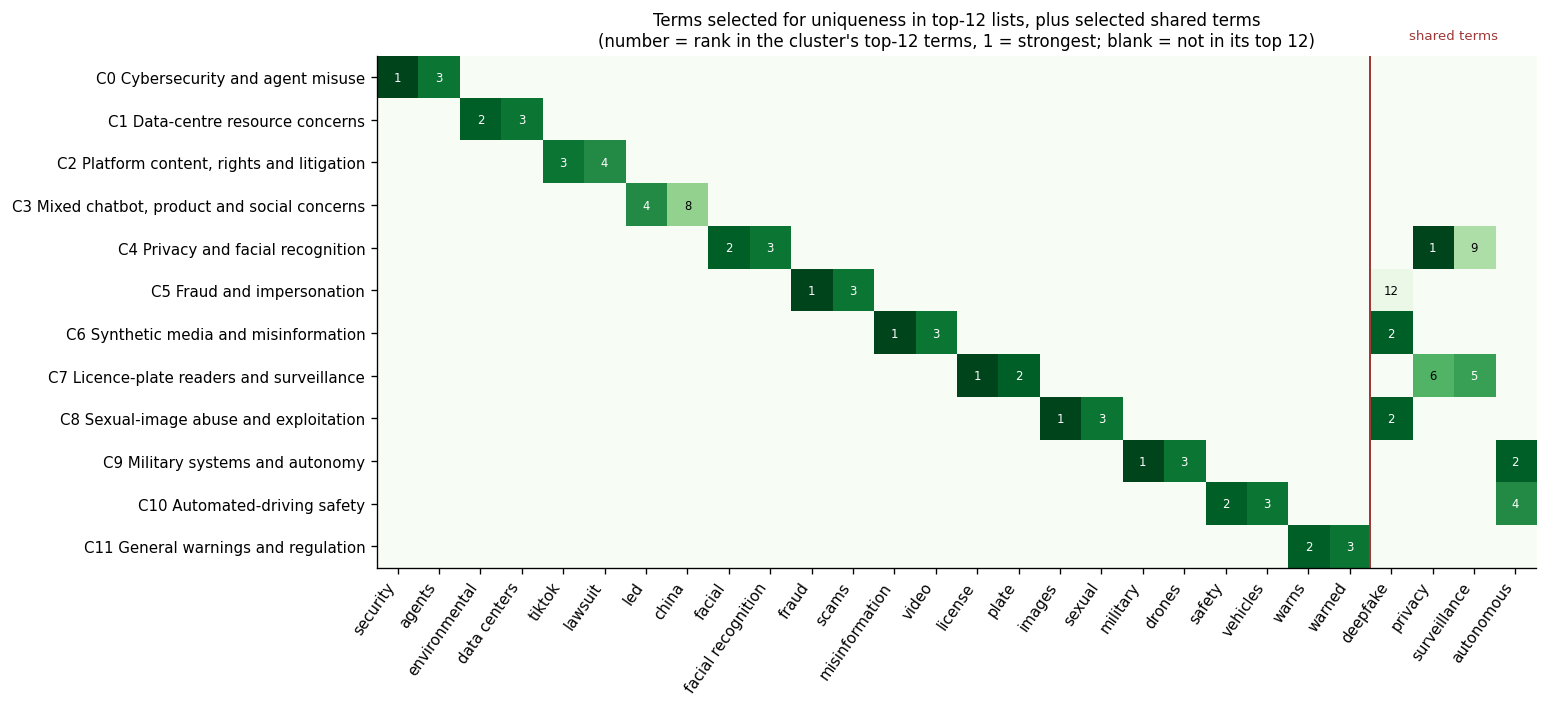

In [ ]:
# Columns: two strongest distinguishing terms per cluster, then four shared terms that link clusters.
picked = []
for p in summary['profiles']:
    distinct = [t for t in p['terms'] if term_counts[t] == 1 and t not in NAME_TERMS]
    picked += distinct[:2]
SHARED_LINKS = [t for t in ['deepfake', 'privacy', 'surveillance', 'autonomous'] if term_counts.get(t, 0) > 1]
columns = picked + SHARED_LINKS
ranks = np.array([[p['terms'].index(t) + 1 if t in p['terms'] else 0 for t in columns] for p in summary['profiles']])
strength = np.where(ranks > 0, (13 - ranks) / 12, 0.0)   # rank 1 -> 1.0, rank 12 -> 0.08, absent -> 0
fig, ax = plt.subplots(figsize=(13, 6))
ax.imshow(strength, aspect='auto', cmap='Greens', vmin=0, vmax=1)
for (i, j), r in np.ndenumerate(ranks):
    if r: ax.text(j, i, str(r), ha='center', va='center', fontsize=7, color='white' if strength[i, j] > .6 else 'black')
ax.set_yticks(range(len(ranks)), [f"C{p['cluster']} {THEMES[p['cluster']]}" for p in summary['profiles']], fontsize=9)
ax.set_xticks(range(len(columns)), columns, rotation=55, ha='right', fontsize=9)
if SHARED_LINKS:
    ax.axvline(len(picked) - .5, color='#a03838', linewidth=1.2)
    ax.text(len(picked) + (len(SHARED_LINKS) - 1) / 2, -0.9, 'shared terms', color='#a03838', ha='center', fontsize=8)
ax.set_title("Terms selected for uniqueness in top-12 lists, plus selected shared terms\n"
             "(number = rank in the cluster's top-12 terms, 1 = strongest; blank = not in its top 12)", fontsize=10)
fig.tight_layout(); plt.show()

### 6.3 Company and product effects
Fraud/impersonation and synthetic misinformation appear in different groups even though both involve deceptive content; the heatmap above shows them linked through *deepfake*. Privacy/facial recognition and licence-plate readers also split, suggesting both thematic similarity and sector or product specificity. The 370-report mixed group remains poorly resolved. Environmental infrastructure concerns form a smaller 45-report queue, but size is not impact severity.

Named-entity concentration is diagnostic: around 40% of the driving-safety queue mentions Tesla, and around 42% of the cybersecurity queue mentions OpenAI. These are mentions, not findings of responsibility. The ten markers overlap, are not an exhaustive entity detector, and omit prominent terms such as Flock. The absence of a marker is not proof a cluster is entity independent.

Overlapping name mentions in the retained corpus:
OpenAI       170
Anthropic    143
Meta         124
Google        91
Claude        82
ChatGPT       80
Tesla         32
Grok          30
Gemini        30
DeepSeek      14


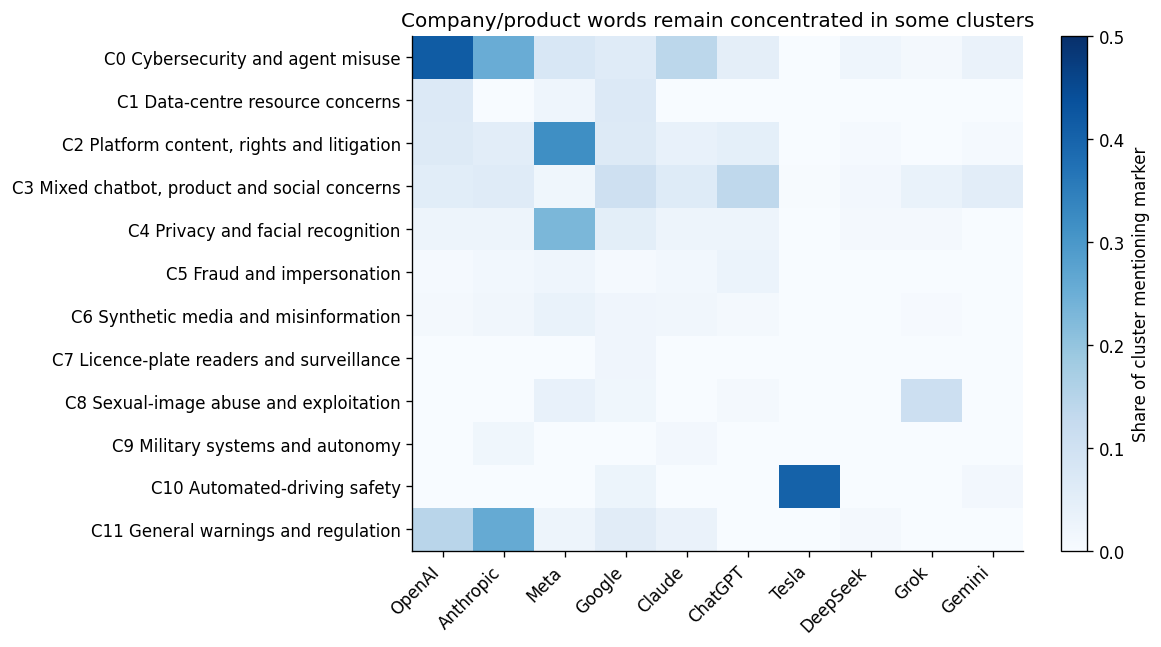

In [ ]:
concentration = pd.DataFrame(summary['concentration']).T
concentration.index = concentration.index.astype(int)
concentration = concentration.sort_index()
print('Overlapping name mentions in the retained corpus:\n' + pd.Series(summary['mentions']).sort_values(ascending=False).to_string())
fig, ax=plt.subplots(figsize=(10,5.5))
im=ax.imshow(concentration.to_numpy(),aspect='auto',cmap='Blues',vmin=0,vmax=.5)
ax.set_yticks(range(len(concentration)),[f'C{i} {THEMES.get(i, "")}' for i in concentration.index])
ax.set_xticks(range(len(concentration.columns)),concentration.columns,rotation=45,ha='right')
ax.set(title='Company/product words remain concentrated in some clusters')
fig.colorbar(im,ax=ax,label='Share of cluster mentioning marker');fig.tight_layout();plt.show()

## 7. Findings, decision and next experiments
The answer to the research question is **partial and conditional**. Text clustering exposes recognisable candidate themes, but the experiment does not demonstrate stable harm categories independent of news topics. Shared entities, applications and reporting language still shape grouping. Low separation, a large mixed cluster, incomplete scope checks and sensitivity to refitting constrain interpretation.

Section 6.1a examines the mixed groups more closely: C2 combines child protection and creative-rights questions; C3 combines employment concerns and reliance on unreliable outputs; C11 combines broad warnings and sectoral financial risks. These illustrative contrasts suggest different review routes without establishing new subclusters or their prevalence.

**Verdict on the hypotheses (Section 1.1)**
- **H1, harm mechanism: partly supported.** Keywords and central examples suggest candidate harm or sector themes including data-centre resources, privacy and facial recognition, fraud and impersonation, synthetic media and misinformation, licence-plate surveillance, sexual-image abuse, and military autonomy. This is not an audited count of coherent harm mechanisms: military autonomy is an application area, and the licence-plate queue may be product-led (Flock is absent from the ten-name detector). The large mixed group (370 reports) and the general-warnings group combine several harms.
- **H2, entity/news effect: partly supported.** Names concentrate in some clusters: about 42% of the cybersecurity group mentions OpenAI, about 40% of the driving-safety group mentions Tesla, and about 32% of the platform-litigation group mentions Meta. Masking ten names changes membership (ARI 0.647). ARI alone does not establish whether the masked clusters preserve the same themes; that requires a separate interpretation audit.
- **H3, weak separation: supported.** Original-space silhouette is 0.027, 21.1% of reports have negative silhouette, seed agreement ranges from ARI 0.573 to 0.671, subset agreement with a fixed seed from 0.515 to 0.668, and one mixed group is twice the size of most others.

For this fixed corpus, LSA/K-means is a reasonable illustrative reading aid among the tested settings. It should not automatically assign risk severity, establish factual claims, or determine which harms deserve the most resources. The highest-scoring k is at the upper grid boundary, and Section 5.3 shows separation keeps rising slowly up to k = 20 (silhouette 0.033). k = 12 is therefore a practical ceiling for a reading queue, not a natural number of themes; the analyst-defined exploratory 4–12 group rule is unchanged. It was not preregistered or validated as a usability requirement.

Next steps, in priority order: complete relevance and event verification; run the independent coherence audit; compare a pinned, licensed sentence-embedding model with the same evaluation protocol; examine additional LSA dimensions and, given the small continued gains in Section 5.3, whether reviewers find a larger number of narrower queues practical; test a separately collected quarter. Keep these tests explicit rather than presenting them as work already completed. Verify representative original sources before discussing named cases as facts.

## 8. Reflection: Framing, Methods & Insights
### 8.1 How my framing shaped the data and evaluation choices
I started out wanting to find recurring themes in documented AI harms. Exploring the data changed that goal quickly. A large number of reports doesn't mean a large number of independent harmful events: one report can describe a possible future hazard, revisit ongoing litigation, combine several developments or simply repeat a dominant product name. That pushed me to a sharper question: can a cluster tell us anything useful about harm beyond shared news vocabulary? Once I framed it that way, the highest silhouette score could no longer be my only criterion. I also needed coverage, stability and evidence about entity effects.

I chose a single recent quarter so that collection stayed manageable and auditable. That choice also limits what I can claim. The reporting window describes the media coverage the monitor captured at one point in time, not when or how often harms occurred worldwide. Moving from my January–February 2025 pilot to this quarter reduced the dominance of DeepSeek but didn't remove news effects in general. When separation stayed weak, I kept the period anyway. Switching datasets until the scores looked better would have undermined the exploratory purpose of the work.

For the same reason I kept the report as the unit of analysis. I excluded the existing OECD concept tags from the features, because they would bring upstream classifications into a supposedly unsupervised result. The country and company fields were unsuitable as inputs: country was sometimes missing and company was empty for every report. Titles and summaries were a transparent, consistent starting point. Joining them added context, but the summary-only experiment showed how much that one decision changed the grouping.

### 8.2 What the methods offered, and what they couldn't do
TF-IDF was useful because I could trace every feature back to a word or phrase. Its weakness was just as clear. Two descriptions with similar meaning but different wording can end up far apart, while a repeated company or product name can pull unrelated harms together. Filtering rare terms reduced noise but may hide uncommon, serious harms. I came to see this as an equity issue: a harm that is rarely reported should not, in effect, become low priority for the people it affects.

LSA compressed 6,110 features into 100 dimensions. It made clusters more compact in the reduced space but kept only about a quarter of the variance, and separation in the original space improved only slightly. The lesson I take from this is that a cleaner numerical representation can make a projection look more organised without answering the research question. LSA is derived from word patterns in this corpus; it doesn't understand sentences, and I didn't evaluate any pretrained semantic model.

K-means gave me a complete reading queue at low computational cost, but membership shifted with the random seed and with refitting. Twenty initialisations reduced dependence on a single start without removing that instability. Average-linkage hierarchical clustering was deterministic and offered a nested view of similarity, but some cuts produced very small groups and lower separation. DBSCAN taught me the most about evaluation traps. At a tight radius it found compact groups with an attractive silhouette while leaving more than 90% of reports unassigned. At a medium radius it fragmented into about thirty tiny groups, and at wider radii everything merged into one cluster. For a whole-corpus review queue, losing that much coverage outweighed the attractive score.

Writing down explicit selection constraints made my choice transparent, but I set those constraints myself during exploratory work, not from external requirements. Choosing k = 12 at the edge of the grid doesn't show that twelve themes exist in the world, which is why I added the wider check in Section 5.3. Separation kept creeping upwards to k = 20 but stayed close to zero, which confirmed for me that the number of groups is a practical choice for reviewers rather than something the data settles. Because I tuned and evaluated on the same corpus, the final score describes this dataset rather than predicting future performance.

### 8.3 How well the results matched my objectives
The study partly met its objective. Fraud, surveillance, sexual-image abuse, misinformation, data-centre resource concerns and vehicle safety came out as recognisable candidate themes, and these queues could genuinely help a reviewer start reading related material. At the same time, the large mixed chatbot/product group and the separate licence-plate-reader group show that the model mixes harm types, sectors and named technologies. The result doesn't justify calling every group a harm category.

The most important insight for me was the tension between interpretability and stability. A list of top terms can look convincing even when membership changes substantially between runs. Original-space silhouette values near zero and moderate ARI values made me write that limitation into the conclusion instead of the convincing labels. Removing just four possible repeat stories changed the partition noticeably, which shows why a small deduplication test can't establish that reports are independent. Masking ten names also left many aliases and story details untouched. I learned that robustness needs several complementary checks, not one diagnostic that happens to pass.

### 8.4 Challenges, research integrity and lessons for future work
My main practical challenge was building a reproducible project on a monitor that changes over time and caps each download at 100 rows. I used 22 overlapping exports, stable report IDs, a collection manifest and a checksum to keep an audit trail. These can't make a future download identical, so the exact snapshot has to stay available privately for the original analysis to be reproduced. I therefore made the notebook clearly separate full computation, aggregate replay and new-snapshot runs, and never silently substitute one for another.

Relevance screening is the other substantive limit. The targeted preliminary screening covered only 181 summaries closely, so retaining 1,845 reports is provisional. Stronger claims would need a full human audit, a consistent distinction between incidents and hazards, and verification of repeated events. Central examples helped me interpret clusters but are not a random coherence test. Next time I would build in two-reviewer assessments, with recorded disagreements, before finalising the theme labels.

Finally, I learned that rights questions are part of responsible data work. A publicly accessible website doesn't settle whether its exported text can be redistributed. Keeping the source descriptions out of the package while providing loading instructions was my practical answer while clarification is pending. I also used AI assistance during the project, and I disclose this in Section 10. The main lesson I take away is that a useful capstone can document the limits of a promising-looking method. An honest account of what the clusters cannot support is itself relevant to AI governance.

## 9. Impact Brief (for Non-Technical Stakeholders)
A short brief for governance, policy and research teams.

**Two terms used throughout**
- **AIM** is the OECD AI Incidents and Hazards Monitor, a public database that collects news reports about actual harms or plausible potential harms, involving AI.
- A **review queue** is a group of similar reports that a reviewer would read together, like a themed reading pile. The computer suggested the groups; a person still has to check them.

### The problem
Governance teams receive more reports about AI than they can easily read and compare. Related concerns can be scattered across sectors, while repeated news coverage of one company can make an issue look more common than it is. This project tests whether a computer can sort the reports into sensible reading piles as a starting point for human review.

### The data
The study uses **1,889 AIM reports dated July–September 2026**. After automated candidate screening and targeted close reading, 6 reports were proposed for exclusion and 38 marked uncertain; these 44 were set aside provisionally, leaving **1,845**. Only 181 reports were read closely for that check, so it's provisional. The reports are news-based descriptions, not independently verified events.

### What we found
The computer suggested **twelve review queues**. Their keywords and central examples suggest candidate themes including fraud and voice impersonation, misleading synthetic media, privacy and facial recognition, licence-plate surveillance, sexual-image abuse, military systems, and data-centre energy and water concerns. These mix types of harm with application areas, and their thematic coherence has not been independently audited. Others mix several topics, and the largest (370 reports about chatbots, products and general concerns) still needs sorting by hand.

**Visual 1 — How many reports fall in each suggested queue**

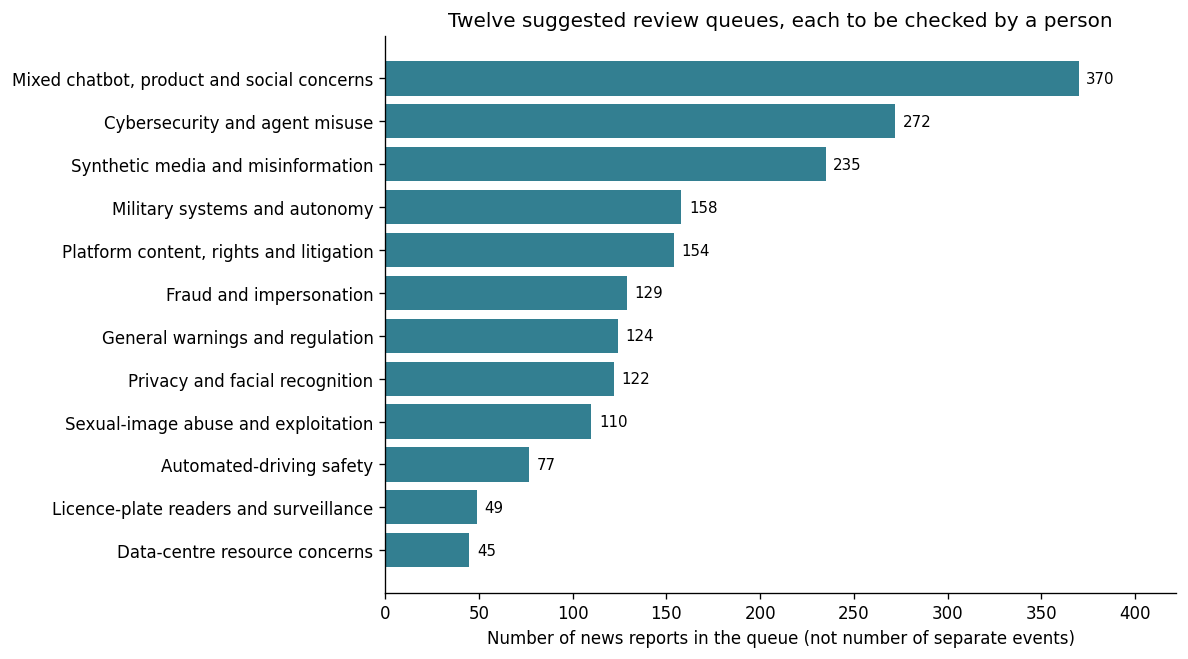

In [ ]:
p = profile_table.sort_values('Reports')
fig, ax = plt.subplots(figsize=(10,5.6))
ax.barh(p['Candidate interpretation'],p.Reports,color='#337f91')
for i,v in enumerate(p.Reports): ax.text(v+4,i,str(v),va='center',fontsize=9)
ax.set(xlabel='Number of news reports in the queue (not number of separate events)',title='Twelve suggested review queues, each to be checked by a person',xlim=(0,p.Reports.max()*1.14))
fig.tight_layout();plt.show()

**Visual 2 — Do the queues stay the same if we change the input slightly?**
We repeated the sorting four times, changing one thing each time: hiding company and product names, dropping headlines, removing a few likely repeat stories, and keeping the uncertain reports. The chart shows how closely each repeat matched the main result, where 1 means identical and 0 means no better than chance. None reaches 1 and most are around 0.6, indicating that the grouping changes under these alternative inputs. These agreement scores do not tell us what percentage of reports changed groups.

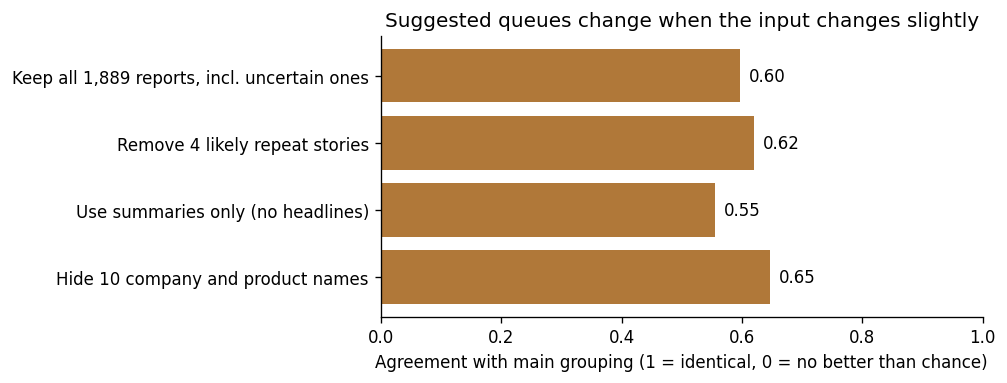

In [ ]:
PLAIN_LABELS = {'Mask 10 company/product names': 'Hide 10 company and product names',
                'Summary only': 'Use summaries only (no headlines)',
                'Thin four probable event families': 'Remove 4 likely repeat stories'}
plain = lambda t: PLAIN_LABELS.get(t, t.replace('Include all', 'Keep all') + ', incl. uncertain ones' if t.startswith('Include all') else None)
view = sensitivity_table.assign(label=sensitivity_table.test.map(plain)).dropna(subset=['label'])
fig, ax=plt.subplots(figsize=(8.5,3.3))
ax.barh(view.label,view.ari,color='#b07839')
for i,v in enumerate(view.ari):ax.text(v+.015,i,f'{v:.2f}',va='center')
ax.set(xlim=(0,1),xlabel='Agreement with main grouping (1 = identical, 0 = no better than chance)',title='Suggested queues change when the input changes slightly')
fig.tight_layout();plt.show()

### What this means
The groups offer candidate reading themes, but their usefulness has not been evaluated with reviewers. Some also reflect who is in the news: about 4 in 10 automated-driving reports mention Tesla, and about 4 in 10 cybersecurity reports mention OpenAI. These are mentions, not findings of responsibility. Smaller queues include data-centre resource concerns (45 reports) and licence-plate surveillance (49), but a smaller queue is not a less serious harm.

**Decision supported now:** test the queues in a small supervised review pilot. The results do not support automatic risk scoring, compliance decisions or policy priorities based on queue size.

**Visual 3 — Practical uses to test with reviewers**

| Suggested queue | Proposed action | What must be checked first? |
|---|---|---|
| Fraud and impersonation | Add impersonation scenarios to staff awareness and incident intake | Confirm how scams worked and separate repeat coverage from new events |
| Privacy and surveillance | Ask who can access data, how long it is kept and how it could be misused | Read original sources and consider affected people and context |
| Sexual-image abuse and exploitation | Include safeguarding and abuse-response questions | Use trained reviewers and confirm accuracy and relevance |
| Data-centre resource concerns | Ask projects for energy and water evidence alongside benefits | Check measured local impacts; news volume is not an environmental footprint |

These are proposed questions, not actions shown by this study to reduce harm.

### Who should do what
**Governance teams:** give an analyst responsibility for checking reports and candidate themes before use. Preserve IDs and source links, keep uncertainty visible, and allow more than one theme per report. A queue number must not determine responsibility or severity.

**Policy teams:** use verified examples to broaden consultation and scenario planning. Include smaller queues. Combine reporting data with evidence about affected people, exposure and severity when allocating resources.

**Researchers:** complete scope and repeated-event checks, then have two independent reviewers assess random reports from every queue and record disagreements. Compare assisted and ordinary reading using review time and relevant cases missed. Test another quarter and sentence embeddings before generalising. No time saving has yet been demonstrated.

### Caveats
News coverage is selective; actual and potential harms are mixed; summaries may be inaccurate; several reports may describe one event. Only 181 summaries received targeted close review, and no independent thematic audit has been completed. The study does not estimate real-world harm rates, prove legal breaches or measure unequal exposure. OECD source-text redistribution clarification remains pending.

**Takeaway:** these are plausible reading aids to evaluate, with human verification at every stage. Their practical benefit remains a question for the pilot.


In [ ]:
print('Runtime package versions:')
for module in [pd, np, scipy, sklearn, matplotlib]:
    print(module.__name__, module.__version__)
print('Original measured environment:', summary['versions'])
assert len(metrics) == 28
assert sum(p['n'] for p in summary['profiles']) == summary['analysis_n']
assert projection.shape == (summary['analysis_n'], 2)
assert len(final_labels) == len(sample_silhouettes) == summary['analysis_n']
assert np.isfinite(projection).all()
print('Notebook consistency checks passed.')

Runtime package versions:
pandas 2.2.3
numpy 2.3.5
scipy 1.17.0
sklearn 1.8.0
matplotlib 3.10.8
Original measured environment: {'pandas': '2.2.3', 'numpy': '2.3.5', 'scipy': '1.17.0', 'sklearn': '1.8.0', 'matplotlib': '3.10.8'}
Notebook consistency checks passed.
